In [1]:
# Adapted from https://github.com/LeslyLopezFang/Dplus/blob/main/supp_analyses/lesly_reviews_round3_v_responses.ipynb
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib import pyplot as plt

In [2]:
# Helper variables and functions.

alphas = np.arange(0.01, 1.01, 0.01)

xs = np.arange(0.01, 1.01, 0.01)
x_ticks = np.array([
    0.01, 0.1 , 0.2 , 0.3 ,
    0.4 , 0.5 , 0.6 , 0.7 ,
    0.8 , 0.9 , 1,
])

def load_null(fileName):
    dist = []
    for line in open(fileName, 'r'):
        dist.append(float(line))
    return np.array(dist)

def load_performance_no_sprime(pvals, replicatePath):
    performance_dicc = {}
    for stat in ['d', 'dplus', 'dstar', 'hmmix']:
        # For every p-value.
        for pval in pvals:
            # For every window threshold.
            for wind_threshold in [0.05, 0.1, 0.25]:
                # Intialize the column key.
                col_key = f'{stat}-{round(pval, 2)}-{wind_threshold}'
                # Intialize the sub-dictionary.
                performance_dicc[col_key]= {}
                # Intialize the performance counters.
                performance_dicc[col_key]['TP'] = 0
                performance_dicc[col_key]['TN'] = 0
                performance_dicc[col_key]['FP'] = 0
                performance_dicc[col_key]['FN'] = 0
    for rep in range(1, 101):
        performance_df = pd.read_csv(
            f'{replicatePath}/rep{rep}_performance.csv',
        )
        # For every column key.
        for col_key in performance_dicc:
            # For every performance outcome.
            for outcome in performance_dicc[col_key]:
                # Update the reults.
                performance_dicc[col_key][outcome] += (performance_df[col_key].values == outcome).sum()
    return performance_dicc

def load_performance_d_stats(pvals, replicatePath):
    performance_dicc = {}
    for stat in ['d', 'dplus', 'dstar']:
        # For every p-value.
        for pval in pvals:
            # For every window threshold.
            for wind_threshold in [0.05, 0.1, 0.25]:
                # Intialize the column key.
                col_key = f'{stat}-{round(pval, 2)}-{wind_threshold}'
                # Intialize the sub-dictionary.
                performance_dicc[col_key]= {}
                # Intialize the performance counters.
                performance_dicc[col_key]['TP'] = 0
                performance_dicc[col_key]['TN'] = 0
                performance_dicc[col_key]['FP'] = 0
                performance_dicc[col_key]['FN'] = 0
    for rep in range(1, 101):
        performance_df = pd.read_csv(
            f'{replicatePath}/rep{rep}_performance.csv',
        )
        # For every column key.
        for col_key in performance_dicc:
            # For every performance outcome.
            for outcome in performance_dicc[col_key]:
                # Update the reults.
                performance_dicc[col_key][outcome] += (performance_df[col_key].values == outcome).sum()
    return performance_dicc

def load_performance(pvals, replicatePath):
    performance_dicc = {}
    for stat in ['d', 'dplus', 'dstar', 'Sprime', 'hmmix']:
        # For every p-value.
        for pval in pvals:
            # For every window threshold.
            for wind_threshold in [0.05, 0.1, 0.25]:
                # Intialize the column key.
                col_key = f'{stat}-{round(pval, 2)}-{wind_threshold}'
                # Intialize the sub-dictionary.
                performance_dicc[col_key]= {}
                # Intialize the performance counters.
                performance_dicc[col_key]['TP'] = 0
                performance_dicc[col_key]['TN'] = 0
                performance_dicc[col_key]['FP'] = 0
                performance_dicc[col_key]['FN'] = 0
    for rep in range(1, 101):
        performance_df = pd.read_csv(
            f'{replicatePath}/rep{rep}_performance.csv',
        )
        # For every column key.
        for col_key in performance_dicc:
            # For every performance outcome.
            for outcome in performance_dicc[col_key]:
                # Update the reults.
                performance_dicc[col_key][outcome] += (performance_df[col_key].values == outcome).sum()
    return performance_dicc

def calc_performance_metrics(performance_dicc):
    # Intialize a dataframe dictionary.
    df_dicc = {
        'wind_thresh': [], 'pval': [], 'stat': [],
        'tp': [], 'tn': [], 'fp': [], 'fn': [],
        'precision': [], 'recall': [],
    }
    
    for col_key in performance_dicc:
        # Unpack the column key.
        stat, pval, wind_threshold = col_key.split('-')
        # Extract the performance outcomes.
        tp = performance_dicc[col_key]['TP']
        tn = performance_dicc[col_key]['TN']
        fp = performance_dicc[col_key]['FP']
        fn = performance_dicc[col_key]['FN']
        # Compute precision.
        precision = tp / (tp + fp)
        # Compute recall.
        recall = tp / (tp + fn)
        # Update the dictionary.
        df_dicc['wind_thresh'].append(float(wind_threshold))
        df_dicc['pval'].append(float(pval))
        df_dicc['stat'].append(stat)
        df_dicc['tp'].append(tp)
        df_dicc['tn'].append(tn)
        df_dicc['fp'].append(fp)
        df_dicc['fn'].append(fn)
        df_dicc['precision'].append(precision)
        df_dicc['recall'].append(recall)
        
    return pd.DataFrame(data=df_dicc)

def print_precision_recall(df):
    cond_wind = df['wind_thresh'] == 0.1
    cond_d = df['stat'] == 'd'
    cond_dplus = df['stat'] == 'dplus'
    cond_dstar = df['stat'] == 'dstar'
    cond_sprime = df['stat'] == 'Sprime'
    cond_hmmix = df['stat'] == 'hmmix'
    print("alpha\tD\t\tD+\t\tD*\tSprime\thmmix")
    for i,a in enumerate([0.01, 0.02, 0.03, 0.04, 0.05]):
        print(f"{a}\t{df[cond_wind & cond_d]['precision'].values[i]:.3f}/{df[cond_wind & cond_d]['recall'].values[i]:.3f}\t{df[cond_wind & cond_dplus]['precision'].values[i]:.3f}/{df[cond_wind & cond_dplus]['recall'].values[i]:.3f}\t{df[cond_wind & cond_dstar]['precision'].values[i]:.3f}/{df[cond_wind & cond_dstar]['recall'].values[i]:.3f}\t{df[cond_wind & cond_sprime]['precision'].values[i]:.3f}/{df[cond_wind & cond_sprime]['recall'].values[i]:.3f}\t{df[cond_wind & cond_hmmix]['precision'].values[i]:.3f}/{df[cond_wind & cond_hmmix]['recall'].values[i]:.3f}")
    print()

def print_precision_recall_d_stats(df):
    cond_wind = df['wind_thresh'] == 0.1
    cond_d = df['stat'] == 'd'
    cond_dplus = df['stat'] == 'dplus'
    cond_dstar = df['stat'] == 'dstar'
    print("alpha\tD\t\tD+\t\tD*")
    for i,a in enumerate([0.01, 0.02, 0.03, 0.04, 0.05]):
        print(f"{a}\t{df[cond_wind & cond_d]['precision'].values[i]:.3f}/{df[cond_wind & cond_d]['recall'].values[i]:.3f}\t{df[cond_wind & cond_dplus]['precision'].values[i]:.3f}/{df[cond_wind & cond_dplus]['recall'].values[i]:.3f}\t{df[cond_wind & cond_dstar]['precision'].values[i]:.3f}/{df[cond_wind & cond_dstar]['recall'].values[i]:.3f}")
    print()

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

In [3]:
performance_results_n1 = load_performance_d_stats(alphas, f'./results/n1/intro')
n1 = calc_performance_metrics(performance_results_n1)

In [4]:
n = []
for i, P1 in enumerate([1, 2, 6, 12]):
    n.append([])
    for j, P2 in enumerate([1, 2, 6, 12]):
        print(P1, P2)
        performance_results = load_performance(alphas, f'./results/n/P1_{P1}_P2_{P2}/intro')
        performance_df = calc_performance_metrics(performance_results)
        n[i].append(performance_df)

1 1
1 2
1 6
1 12
2 1
2 2
2 6
2 12
6 1


/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_2415/2706397886.py:119: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


6 2
6 6
6 12
12 1


/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_2415/2706397886.py:119: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


12 2
12 6
12 12


In [5]:
print_precision_recall(n[2][0])
print_precision_recall(n[3][0])

alpha	D		D+		D*	Sprime	hmmix
0.01	0.328/0.010	0.588/0.024	0.894/0.129	0.184/0.009	nan/0.000
0.02	0.405/0.024	0.549/0.044	0.839/0.177	0.193/0.017	0.941/0.002
0.03	0.422/0.037	0.532/0.059	0.805/0.210	0.192/0.023	0.787/0.009
0.04	0.431/0.050	0.508/0.074	0.776/0.239	0.195/0.030	0.742/0.018
0.05	0.445/0.066	0.496/0.088	0.749/0.262	0.197/0.036	0.713/0.027

alpha	D		D+		D*	Sprime	hmmix
0.01	0.372/0.010	0.594/0.027	0.901/0.146	0.161/0.003	nan/0.000
0.02	0.415/0.024	0.579/0.046	0.858/0.197	0.168/0.007	nan/0.000
0.03	0.447/0.040	0.562/0.065	0.827/0.232	0.173/0.011	nan/0.000
0.04	0.454/0.056	0.545/0.080	0.800/0.261	0.191/0.018	nan/0.000
0.05	0.468/0.072	0.534/0.094	0.778/0.288	0.197/0.025	nan/0.000



In [6]:
depolar_n = []
for i, P1 in enumerate([1, 2, 6, 12]):
    depolar_n.append([])
    for j, P2 in enumerate([1, 2, 6, 12]):
        print(P1, P2)
        performance_results = load_performance(alphas, f'./results/depolar_n/P1_{P1}_P2_{P2}/intro')
        performance_df = calc_performance_metrics(performance_results)
        depolar_n[i].append(performance_df)

1 1
1 2
1 6
1 12
2 1
2 2
2 6
2 12
6 1
6 2
6 6
6 12
12 1
12 2
12 6
12 12


In [7]:
drift = []
for i in range(1, 7):
    print(i)
    performance_results = load_performance(alphas, f'./results/drift/scenario{i}/intro')
    performance_df = calc_performance_metrics(performance_results)
    drift.append(performance_df)

1
2
3
4
5
6


In [8]:
molClock = []
for i in range(1, 9):
    print(i)
    performance_results = load_performance(alphas, f'./results/molClock/scenario{i}/intro')
    performance_df = calc_performance_metrics(performance_results)
    molClock.append(performance_df)

1
2
3
4
5
6
7
8


In [9]:
adna = {}
for i in ['no_error', 'pseudo_hap', 'deamin', 'missing', 'all']:
    print(i)
    performance_results = load_performance_d_stats(alphas, f'./results/adna/{i}/intro')
    adna[i] = calc_performance_metrics(performance_results)

no_error
pseudo_hap
deamin
missing
all


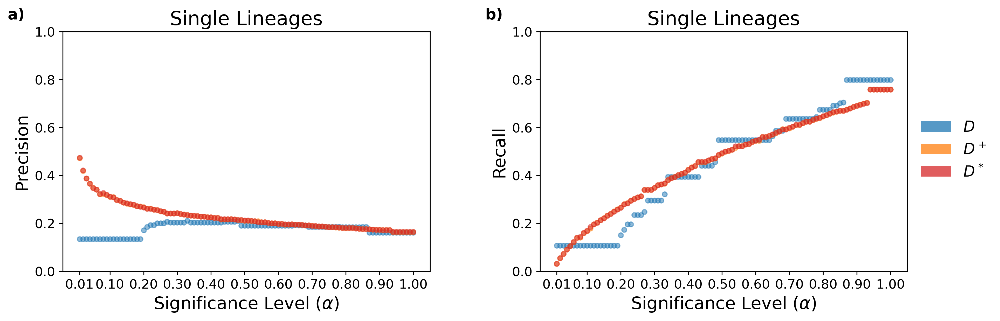

alpha	D		D+		D*
0.01	0.134/0.108	0.472/0.031	0.474/0.031
0.02	0.134/0.108	0.419/0.054	0.421/0.055
0.03	0.134/0.108	0.388/0.072	0.388/0.072
0.04	0.134/0.108	0.366/0.091	0.366/0.091
0.05	0.134/0.108	0.348/0.106	0.348/0.106



In [18]:
fig, axes = plt.subplots(
    1, 2, figsize=(14, 4), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

cond_wind_n1 = n1['wind_thresh'] == 0.1
cond_d_n1 = n1['stat'] == 'd'
cond_dplus_n1 = n1['stat'] == 'dplus'
cond_dstar_n1 = n1['stat'] == 'dstar'

axes[0].scatter(
    xs, n1[cond_wind_n1 & cond_d_n1]['precision'].values,
    marker='o', s=20, color='tab:blue', alpha=0.5,
)
axes[0].scatter(
    xs, n1[cond_wind_n1 & cond_dplus_n1]['precision'].values,
    marker='o', s=20, color='tab:orange', alpha=0.5,
)
axes[0].scatter(
    xs, n1[cond_wind_n1 & cond_dstar_n1]['precision'].values,
    marker='o', s=20, color='tab:red', alpha=0.5,
)
axes[1].scatter(
    xs, n1[cond_wind_n1 & cond_d_n1]['recall'].values,
    marker='o', s=20, color='tab:blue', alpha=0.5,
)
axes[1].scatter(
    xs, n1[cond_wind_n1 & cond_dplus_n1]['recall'].values,
    marker='o', s=20, color='tab:orange', alpha=0.5,
)
axes[1].scatter(
    xs, n1[cond_wind_n1 & cond_dstar_n1]['recall'].values,
    marker='o', s=20, color='tab:red', alpha=0.5,
)
axes[0].set_title("Single Lineages")
axes[0].set_ylabel('Precision')
axes[0].set_xlabel(r'Significance Level ($\alpha$)')
axes[0].set_ylim(0, 1)
axes[0].set_xticks(x_ticks)
axes[1].set_title("Single Lineages")
axes[1].set_ylabel('Recall')
axes[1].set_xlabel(r'Significance Level ($\alpha$)')
axes[1].set_ylim(0, 1)
axes[1].set_xticks(x_ticks)

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.3   # vertical space between subplots
)

# Show the plot.
plt.savefig("single_lineage.png", dpi=300)
plt.show()

print_precision_recall_d_stats(n1)

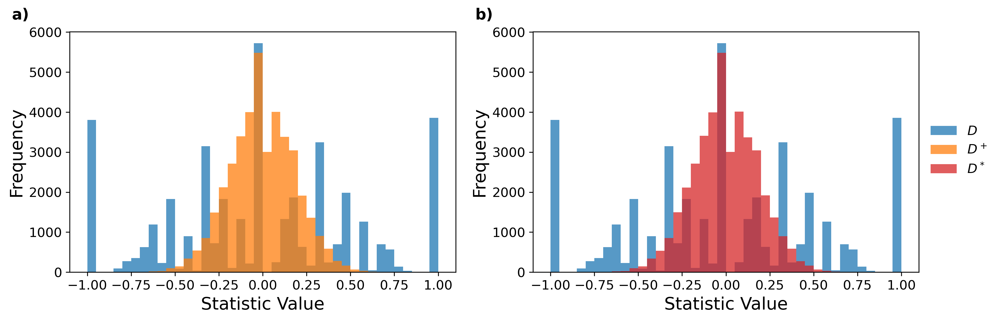

In [5]:
dNull = load_null('results/n1/noIntro/d_null.txt')
dplusNull = load_null('results/n1/noIntro/dplus_null.txt')
dstarNull = load_null('results/n1/noIntro/dstar_null.txt')
fig, axes = plt.subplots(
    1, 2, figsize=(14, 4), dpi=300.0,
    sharex=False, sharey=False, facecolor='white',
)
axes[0].hist(
    dNull, bins=np.arange(-1, 1.05, 0.05),
    histtype='stepfilled', color='tab:blue', alpha=0.75,
)
axes[0].hist(
    dplusNull, bins=np.arange(-1, 1.05, 0.05),
    histtype='stepfilled', color='tab:orange', alpha=0.75,
)
axes[1].hist(
    dNull, bins=np.arange(-1, 1.05, 0.05),
    histtype='stepfilled', color='tab:blue', alpha=0.75,
)
axes[1].hist(
    dstarNull, bins=np.arange(-1, 1.05, 0.05),
    histtype='stepfilled', color='tab:red', alpha=0.75,
)
legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=12,
)
axes[0].set_xlabel('Statistic Value')
axes[0].set_ylabel('Frequency')
axes[1].set_xlabel('Statistic Value')
axes[1].set_ylabel('Frequency')
for ax, label in zip(axes.flat, ['a)', 'b)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )
plt.savefig("n1_null.png", dpi=300)
plt.show()

1 1
1 2
1 6
1 12
2 1
2 2
2 6
2 12
6 1
6 2
6 6
6 12
12 1
12 2
12 6
12 12


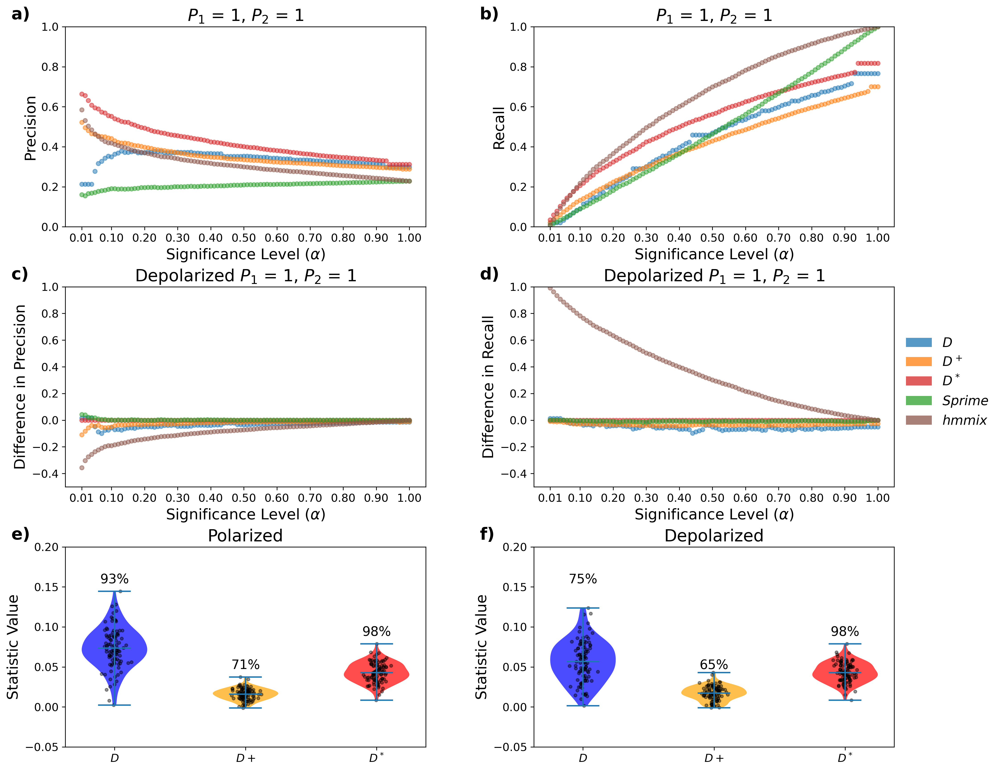

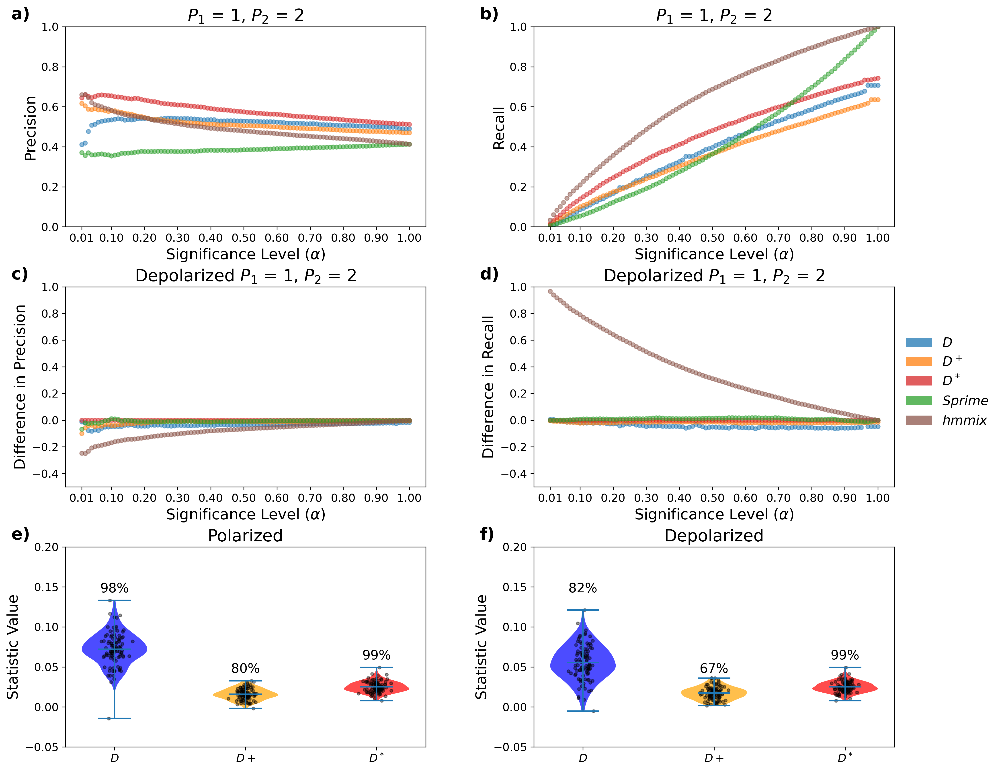

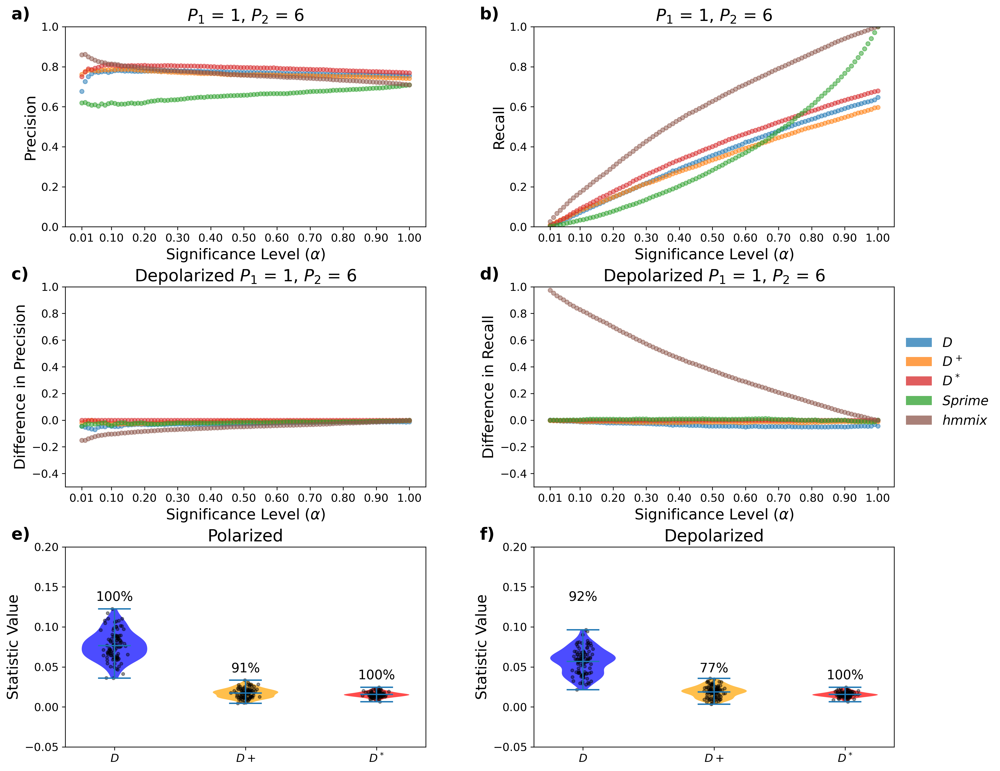

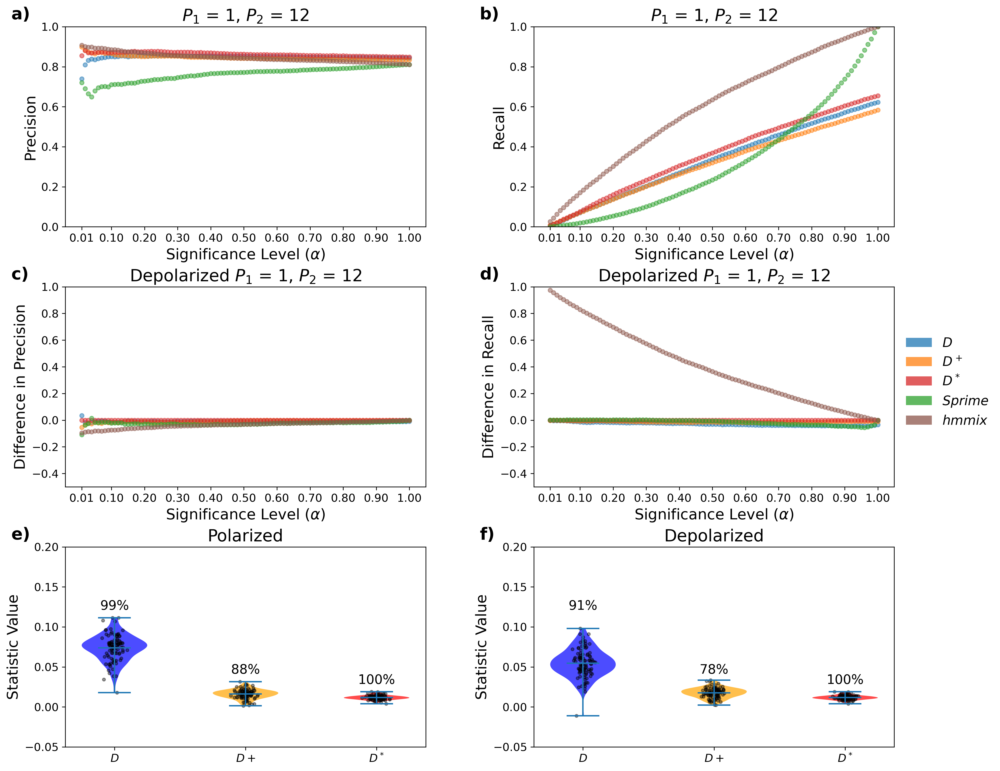

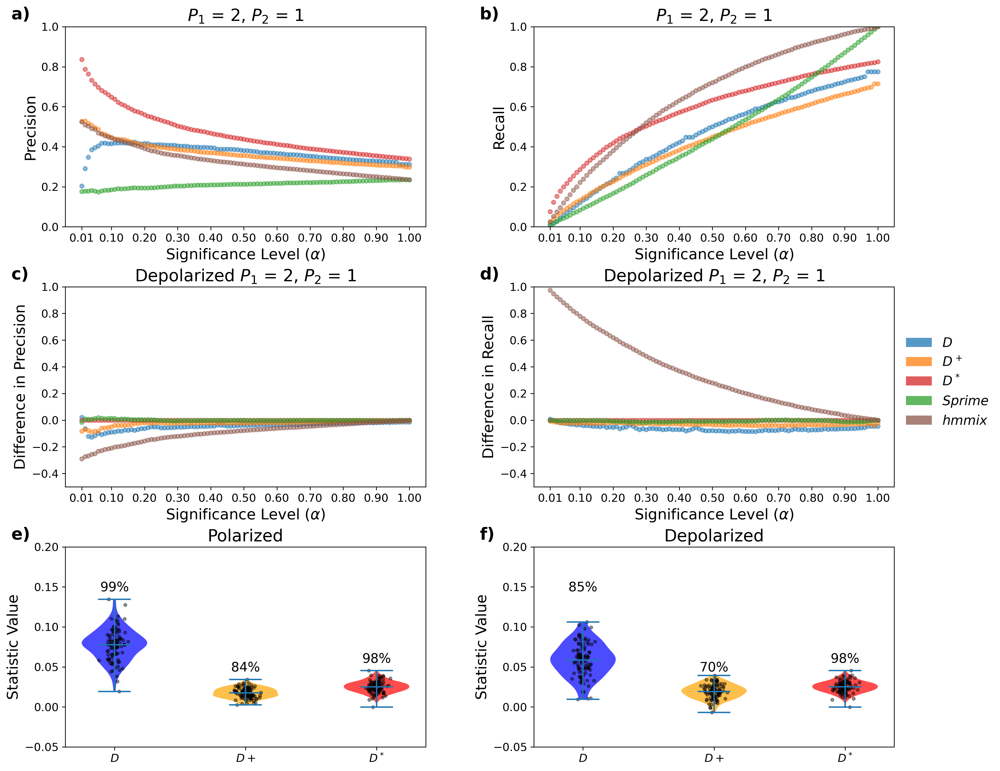

...

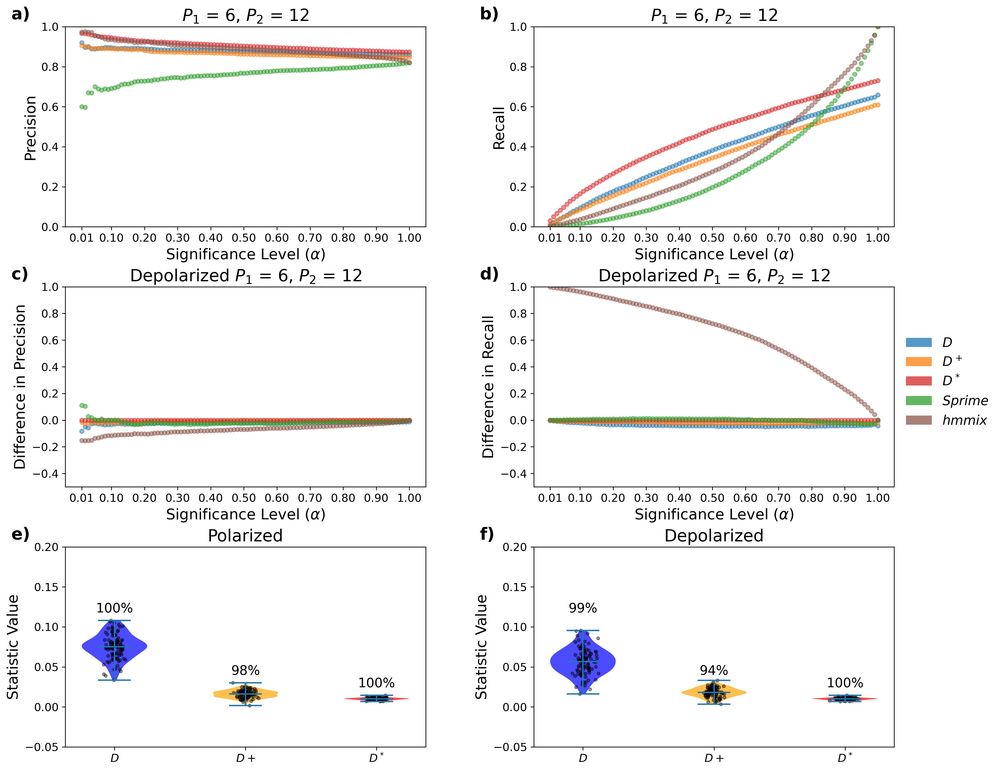

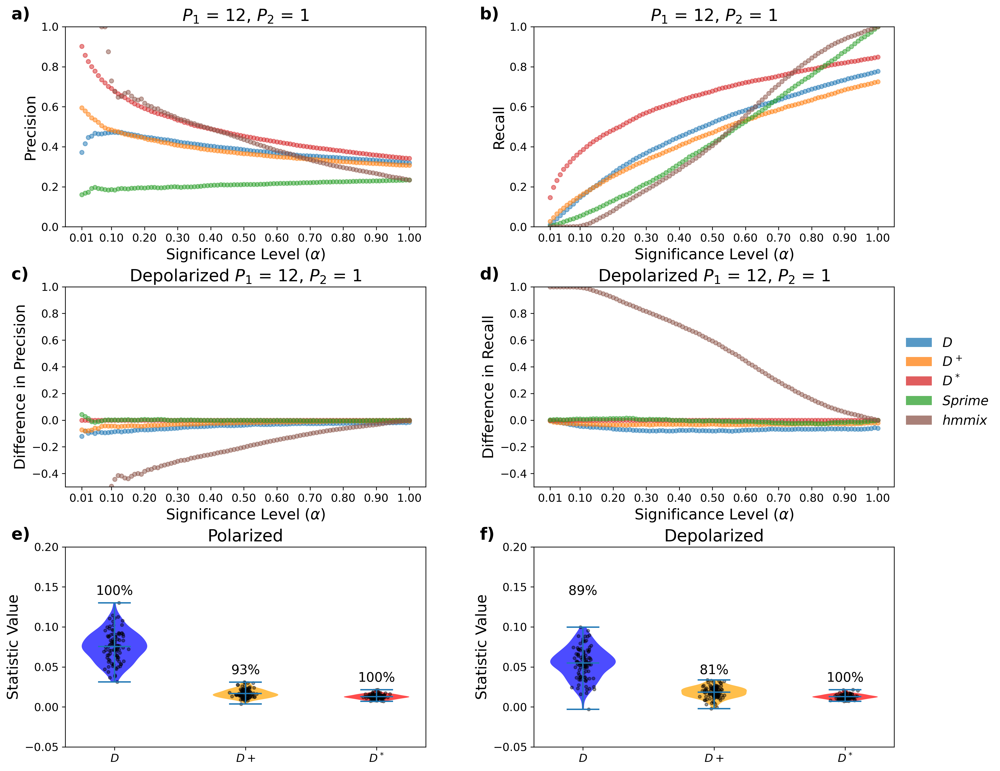

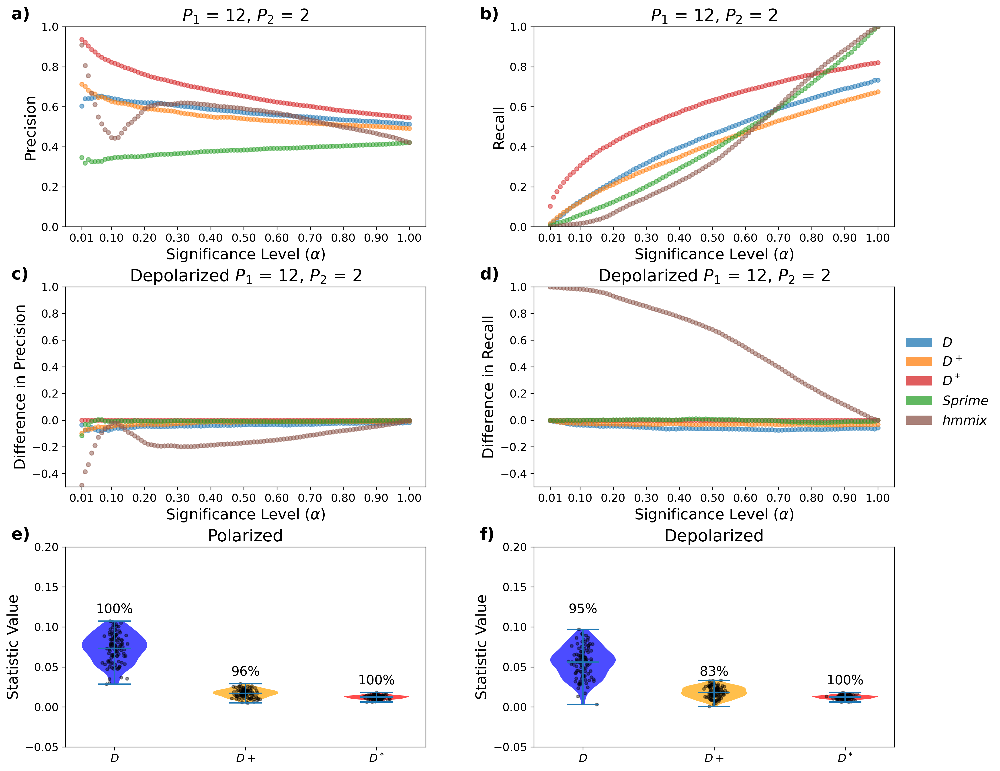

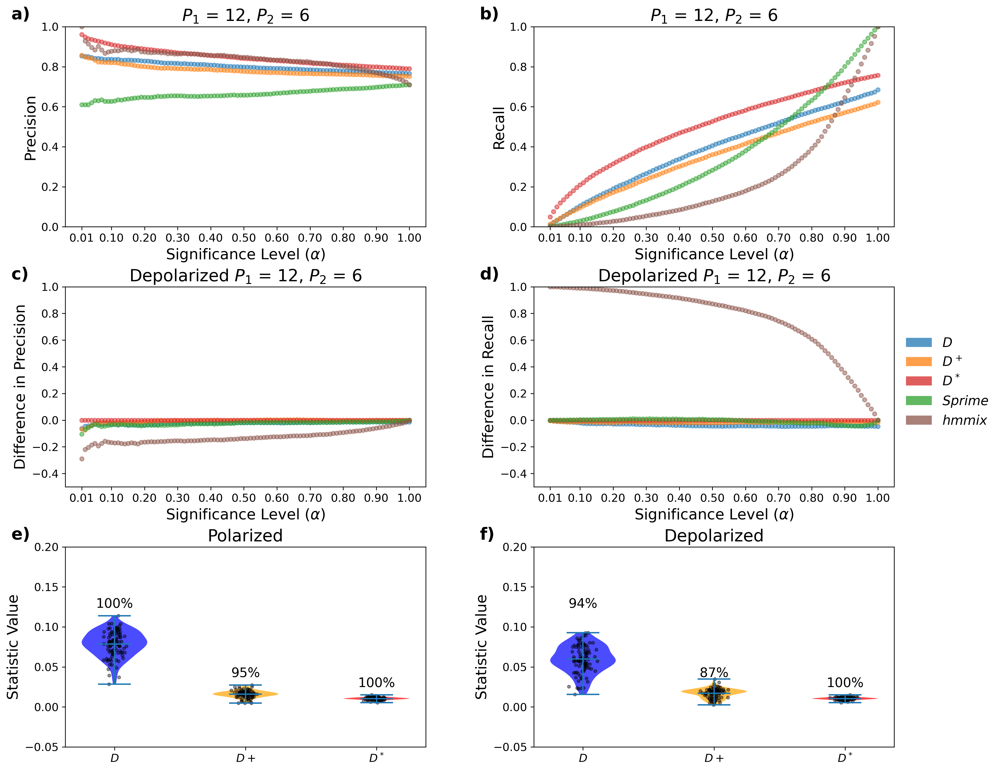

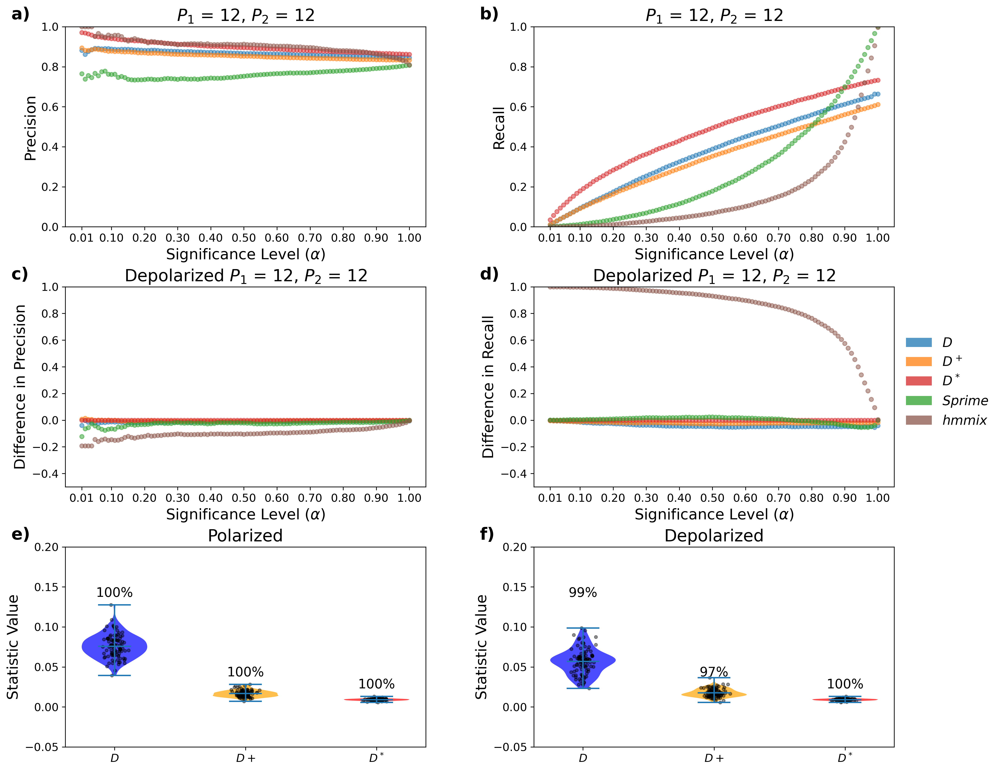

In [11]:

P1 = [1, 2, 6, 12]
P2 = [1, 2, 6, 12]

for p1 in range(4):
    for p2 in range(4):
        print(P1[p1], P2[p2])
        fig, axes = plt.subplots(
            3, 2, figsize=(16, 14), dpi=300.0,
            sharex=False, sharey=False, facecolor='white'
        )
        
        cond_wind = n[p1][p2]['wind_thresh'] == 0.1
        cond_d = n[p1][p2]['stat'] == 'd'
        cond_dplus = n[p1][p2]['stat'] == 'dplus'
        cond_dstar = n[p1][p2]['stat'] == 'dstar'
        cond_sprime = n[p1][p2]['stat'] == 'Sprime'
        cond_hmmix = n[p1][p2]['stat'] == 'hmmix'
        
        axes[0][0].scatter(
            xs, n[p1][p2][cond_wind & cond_d]['precision'].values,
            marker='o', s=20, color='tab:blue', alpha=0.5,
        )
        axes[0][0].scatter(
            xs, n[p1][p2][cond_wind & cond_dplus]['precision'].values,
            marker='o', s=20, color='tab:orange', alpha=0.5,
        )
        axes[0][0].scatter(
            xs, n[p1][p2][cond_wind & cond_dstar]['precision'].values,
            marker='o', s=20, color='tab:red', alpha=0.5,
        )
        axes[0][0].scatter(
            xs, n[p1][p2][cond_wind & cond_sprime]['precision'].values,
            marker='o', s=20, color='tab:green', alpha=0.5,
        )
        axes[0][0].scatter(
            xs, n[p1][p2][cond_wind & cond_hmmix]['precision'].values,
            marker='o', s=20, color='tab:brown', alpha=0.5,
        )
        axes[0][1].scatter(
            xs, n[p1][p2][cond_wind & cond_d]['recall'].values,
            marker='o', s=20, color='tab:blue', alpha=0.5,
        )
        axes[0][1].scatter(
            xs, n[p1][p2][cond_wind & cond_dplus]['recall'].values,
            marker='o', s=20, color='tab:orange', alpha=0.5,
        )
        axes[0][1].scatter(
            xs, n[p1][p2][cond_wind & cond_dstar]['recall'].values,
            marker='o', s=20, color='tab:red', alpha=0.5,
        )
        axes[0][1].scatter(
            xs, n[p1][p2][cond_wind & cond_sprime]['recall'].values,
            marker='o', s=20, color='tab:green', alpha=0.5,
        )
        axes[0][1].scatter(
            xs, n[p1][p2][cond_wind & cond_hmmix]['recall'].values,
            marker='o', s=20, color='tab:brown', alpha=0.5,
        )
        axes[0][0].set_title(f'$P_1$ = {P1[p1]}, $P_2$ = {P2[p2]}')
        axes[0][0].set_ylabel('Precision')
        axes[0][0].set_xlabel(r'Significance Level ($\alpha$)')
        axes[0][0].set_ylim(0, 1)
        axes[0][0].set_xticks(x_ticks)
        axes[0][1].set_title(f'$P_1$ = {P1[p1]}, $P_2$ = {P2[p2]}')
        axes[0][1].set_ylabel('Recall')
        axes[0][1].set_xlabel(r'Significance Level ($\alpha$)')
        axes[0][1].set_ylim(0, 1)
        axes[0][1].set_xticks(x_ticks)
        
        cond_wind_depolar = depolar_n[p1][p2]['wind_thresh'] == 0.1
        cond_d_depolar = depolar_n[p1][p2]['stat'] == 'd'
        cond_dplus_depolar = depolar_n[p1][p2]['stat'] == 'dplus'
        cond_dstar_depolar = depolar_n[p1][p2]['stat'] == 'dstar'
        cond_sprime_depolar = depolar_n[p1][p2]['stat'] == 'Sprime'
        cond_hmmix_depolar = depolar_n[p1][p2]['stat'] == 'hmmix'
        
        axes[1][0].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_d_depolar]['precision'].values - n[p1][p2][cond_wind & cond_d]['precision'].values,
            marker='o', s=20, color='tab:blue', alpha=0.5,
        )
        axes[1][0].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_dplus_depolar]['precision'].values - n[p1][p2][cond_wind & cond_dplus]['precision'].values,
            marker='o', s=20, color='tab:orange', alpha=0.5,
        )
        axes[1][0].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_dstar_depolar]['precision'].values - n[p1][p2][cond_wind & cond_dstar]['precision'].values,
            marker='o', s=20, color='tab:red', alpha=0.5,
        )
        axes[1][0].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_sprime_depolar]['precision'].values - n[p1][p2][cond_wind & cond_sprime]['precision'].values,
            marker='o', s=20, color='tab:green', alpha=0.5,
        )
        axes[1][0].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_hmmix_depolar]['precision'].values - n[p1][p2][cond_wind & cond_hmmix]['precision'].values,
            marker='o', s=20, color='tab:brown', alpha=0.5,
        )
        axes[1][1].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_d_depolar]['recall'].values - n[p1][p2][cond_wind & cond_d]['recall'].values,
            marker='o', s=20, color='tab:blue', alpha=0.5,
        )
        axes[1][1].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_dplus_depolar]['recall'].values - n[p1][p2][cond_wind & cond_dplus]['recall'].values,
            marker='o', s=20, color='tab:orange', alpha=0.5,
        )
        axes[1][1].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_dstar_depolar]['recall'].values - n[p1][p2][cond_wind & cond_dstar]['recall'].values,
            marker='o', s=20, color='tab:red', alpha=0.5,
        )
        axes[1][1].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_sprime_depolar]['recall'].values - n[p1][p2][cond_wind & cond_sprime]['recall'].values,
            marker='o', s=20, color='tab:green', alpha=0.5,
        )
        axes[1][1].scatter(
            xs, depolar_n[p1][p2][cond_wind_depolar & cond_hmmix_depolar]['recall'].values - n[p1][p2][cond_wind & cond_hmmix]['recall'].values,
            marker='o', s=20, color='tab:brown', alpha=0.5,
        )
        axes[1][0].set_title(f'Depolarized $P_1$ = {P1[p1]}, $P_2$ = {P2[p2]}')
        axes[1][0].set_ylabel('Difference in Precision')
        axes[1][0].set_xlabel(r'Significance Level ($\alpha$)')
        axes[1][0].set_ylim(-0.5, 1)
        axes[1][0].set_xticks(x_ticks)
        axes[1][1].set_title(f'Depolarized $P_1$ = {P1[p1]}, $P_2$ = {P2[p2]}')
        axes[1][1].set_ylabel('Difference in Recall')
        axes[1][1].set_xlabel(r'Significance Level ($\alpha$)')
        axes[1][1].set_ylim(-0.5, 1)
        axes[1][1].set_xticks(x_ticks)
        
        global_df = pd.read_csv(f'results/n/P1_{P1[p1]}_P2_{P2[p2]}/intro/global.tsv', sep='\t')
        global_df_depolar = pd.read_csv(f'results/depolar_n/P1_{P1[p1]}_P2_{P2[p2]}/intro/global.tsv', sep='\t')
        positions = [1, 2, 3]
        violins = axes[2][0].violinplot([global_df['D'], global_df['D+'], global_df['D*']], positions=positions, showextrema=True, showmeans = True)
        # Color
        colors = ['blue', 'orange', 'red']
        for body, color in zip(violins['bodies'], colors):
            body.set_facecolor(color)
            body.set_alpha(0.7)
        
        # Overlay points with jitter
        for i, d in enumerate([global_df['D'], global_df['D+'], global_df['D*']]):
            x = np.random.normal(positions[i], 0.04, size=len(d))
            axes[2][0].scatter(x, d, s=10, alpha=0.4, color='black')
        # Add power labels.
        count = np.sum(global_df.iloc[:,4] < 0.05)
        axes[2][0].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,5] < 0.05)
        axes[2][0].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,6] < 0.05)
        axes[2][0].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        axes[2][0].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
        axes[2][0].set_ylabel('Statistic Value')
        axes[2][0].set_ylim((-0.05, 0.2))
        axes[2][0].set_title("Polarized")
        
        violins_depolar = axes[2][1].violinplot([global_df_depolar['D'], global_df_depolar['D+'], global_df_depolar['D*']], positions=positions, showextrema=True, showmeans = True)
        # Color
        colors = ['blue', 'orange', 'red']
        for body, color in zip(violins_depolar['bodies'], colors):
            body.set_facecolor(color)
            body.set_alpha(0.7)
        
        # Overlay points with jitter
        for i, d in enumerate([global_df_depolar['D'], global_df_depolar['D+'], global_df_depolar['D*']]):
            x = np.random.normal(positions[i], 0.04, size=len(d))
            axes[2][1].scatter(x, d, s=10, alpha=0.4, color='black')
        # Add power labels.
        count = np.sum(global_df_depolar.iloc[:,4] < 0.05)
        axes[2][1].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df_depolar.iloc[:,5] < 0.05)
        axes[2][1].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df_depolar.iloc[:,6] < 0.05)
        axes[2][1].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        axes[2][1].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
        axes[2][1].set_ylabel('Statistic Value')
        axes[2][1].set_ylim((-0.05, 0.2))
        axes[2][1].set_title("Depolarized")
        
        legend_elements = [
            Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
            Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
            Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
            Patch(facecolor='tab:green', alpha=0.75, label=r'$Sprime$'),
            Patch(facecolor='tab:brown', alpha=0.75, label=r'$hmmix$')
        ]
        fig.legend(
            handles=legend_elements, loc='center left',
            bbox_to_anchor=(0.9, 0.5), frameon=False,
            fontsize=14,
        )
        
        for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']):
            ax.text(
                -0.15, 1.1, label,
                transform=ax.transAxes,
                fontsize=18,
                fontweight='bold',
                va='top',
                ha='left'
            )
        
        fig.subplots_adjust(
            wspace=0.3,  # horizontal space between subplots
            hspace=0.3   # vertical space between subplots
        )
        
        # Show the plot.
        plt.savefig(f'n_{P1[p1]}_{P2[p2]}.png', dpi=300)

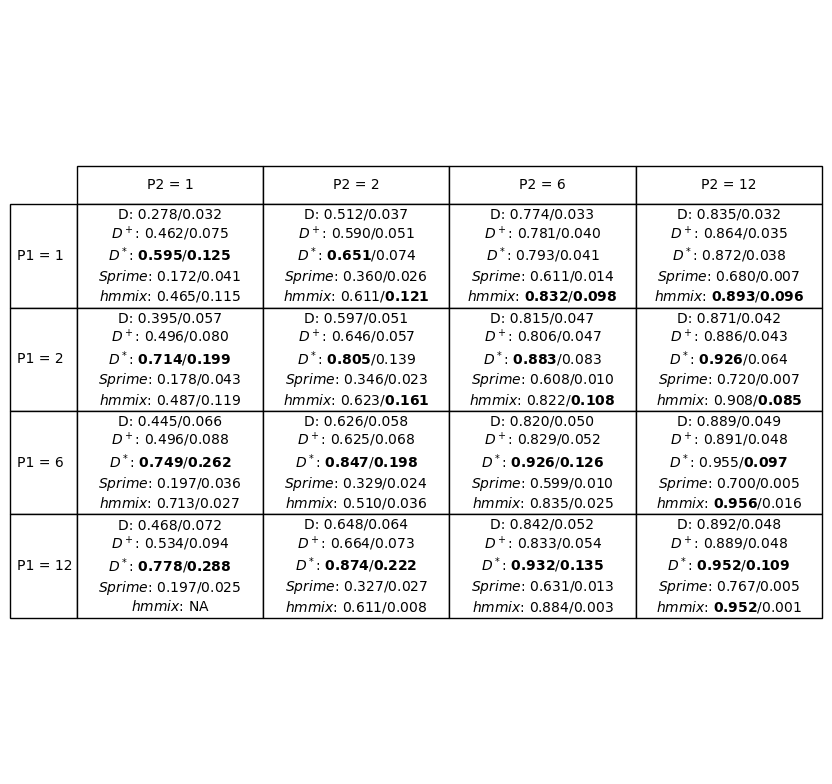

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

def format_max(values):
    """Format values to 3 decimals, bolding the maximum."""
    max_idx = np.nanargmax(values)

    formatted = []

    for i, value in enumerate(values):
        if i == max_idx:
            formatted.append(f"$\\mathbf{{{value:.3f}}}$")
        else:
            formatted.append(f"{value:.3f}")

    return formatted


cell_text = []
for p1 in range(4):
    row = []
    for p2 in range(4):
        cond_wind = n[p1][p2]['wind_thresh'] == 0.1
        cond_d = n[p1][p2]['stat'] == 'd'
        cond_dplus = n[p1][p2]['stat'] == 'dplus'
        cond_dstar = n[p1][p2]['stat'] == 'dstar'
        cond_sprime = n[p1][p2]['stat'] == 'Sprime'
        cond_hmmix = n[p1][p2]['stat'] == 'hmmix'
        d_prec = n[p1][p2][cond_wind & cond_d]['precision'].values[4]
        d_recall = n[p1][p2][cond_wind & cond_d]['recall'].values[4]
        dplus_prec = n[p1][p2][cond_wind & cond_dplus]['precision'].values[4]
        dplus_recall = n[p1][p2][cond_wind & cond_dplus]['recall'].values[4]
        dstar_prec = n[p1][p2][cond_wind & cond_dstar]['precision'].values[4]
        dstar_recall = n[p1][p2][cond_wind & cond_dstar]['recall'].values[4]
        sprime_prec = n[p1][p2][cond_wind & cond_sprime]['precision'].values[4]
        sprime_recall = n[p1][p2][cond_wind & cond_sprime]['recall'].values[4]
        hmmix_prec = n[p1][p2][cond_wind & cond_hmmix]['precision'].values[4]
        hmmix_recall = n[p1][p2][cond_wind & cond_hmmix]['recall'].values[4]
        # Precision
        prec_values = [
            d_prec,
            dplus_prec,
            dstar_prec,
            sprime_prec,
            hmmix_prec
        ]
        
        d_prec, dplus_prec, dstar_prec, sprime_prec, hmmix_prec = format_max(prec_values)
        
        
        # Recall
        recall_values = [
            d_recall,
            dplus_recall,
            dstar_recall,
            sprime_recall,
            hmmix_recall
        ]
        
        d_recall, dplus_recall, dstar_recall, sprime_recall, hmmix_recall = format_max(recall_values)

        if p1 == 3 and p2 == 0:
            text = (
                f"D: {d_prec}/{d_recall}\n"
                f"$D^+$: {dplus_prec}/{dplus_recall}\n"
                f"$D^*$: {dstar_prec}/{dstar_recall}\n"
                f"$Sprime$: {sprime_prec}/{sprime_recall}\n"
                f"$hmmix$: NA"
            )
        elif p1 == 3 and p2 == 3:
            text = (
                f"D: {d_prec}/{d_recall}\n"
                f"$D^+$: {dplus_prec}/{dplus_recall}\n"
                f"$D^*$: $\\mathbf{{{dstar_prec}}}$/{dstar_recall}\n"
                f"$Sprime$: {sprime_prec}/{sprime_recall}\n"
                f"$hmmix$: {hmmix_prec}/{hmmix_recall}"
            )
        else:
            text = (
                f"D: {d_prec}/{d_recall}\n"
                f"$D^+$: {dplus_prec}/{dplus_recall}\n"
                f"$D^*$: {dstar_prec}/{dstar_recall}\n"
                f"$Sprime$: {sprime_prec}/{sprime_recall}\n"
                f"$hmmix$: {hmmix_prec}/{hmmix_recall}"
            )

        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P1 = {x}" for x in P1],
    colLabels=[f"P2 = {x}" for x in P2],
    cellLoc='center',
    loc='center'
)
for j in range(4):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 5)
plt.tight_layout()
plt.savefig("n_table.png", dpi=300)
plt.show()


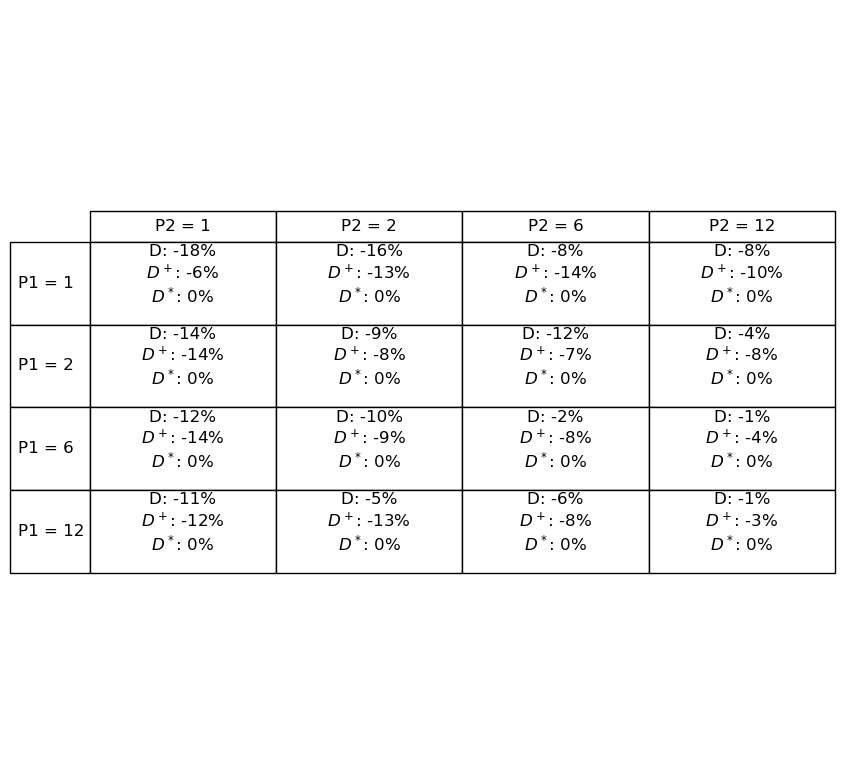

In [44]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

def format_min(values):
    min_idx = np.nanargmin(values)

    formatted = []

    for i, value in enumerate(values):
        if i == min_idx:
            formatted.append(f"$\\mathbf{{{value:.3f}}}$")
        else:
            formatted.append(f"{value:.3f}")

    return formatted

cell_text = []
for p1 in range(4):
    row = []
    for p2 in range(4):
        global_df = pd.read_csv(f'results/n/P1_{P1[p1]}_P2_{P2[p2]}/intro/global.tsv', sep='\t')
        global_df_depolar = pd.read_csv(f'results/depolar_n/P1_{P1[p1]}_P2_{P2[p2]}/intro/global.tsv', sep='\t')
        d_count = np.sum(global_df.iloc[:,4] < 0.05)
        dplus_count = np.sum(global_df.iloc[:,5] < 0.05)
        dstar_count = np.sum(global_df.iloc[:,6] < 0.05)

        d_depolar_count = np.sum(global_df_depolar.iloc[:,4] < 0.05)
        dplus_depolar_count = np.sum(global_df_depolar.iloc[:,5] < 0.05)
        dstar_depolar_count = np.sum(global_df_depolar.iloc[:,6] < 0.05)
        difference = [
            d_depolar_count - d_count,
            dplus_depolar_count - dplus_count,
            dstar_depolar_count - dstar_count
        ]
        text = (
            f"D: {difference[0]}%\n"
            f"$D^+$: {difference[1]}%\n"
            f"$D^*$: {difference[2]}%\n"
        )
        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P1 = {x}" for x in P1],
    colLabels=[f"P2 = {x}" for x in P2],
    cellLoc='center',
    loc='center'
)
for j in range(4):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 4)
plt.tight_layout()
plt.savefig("depolar_n_table.png", dpi=300)
plt.show()

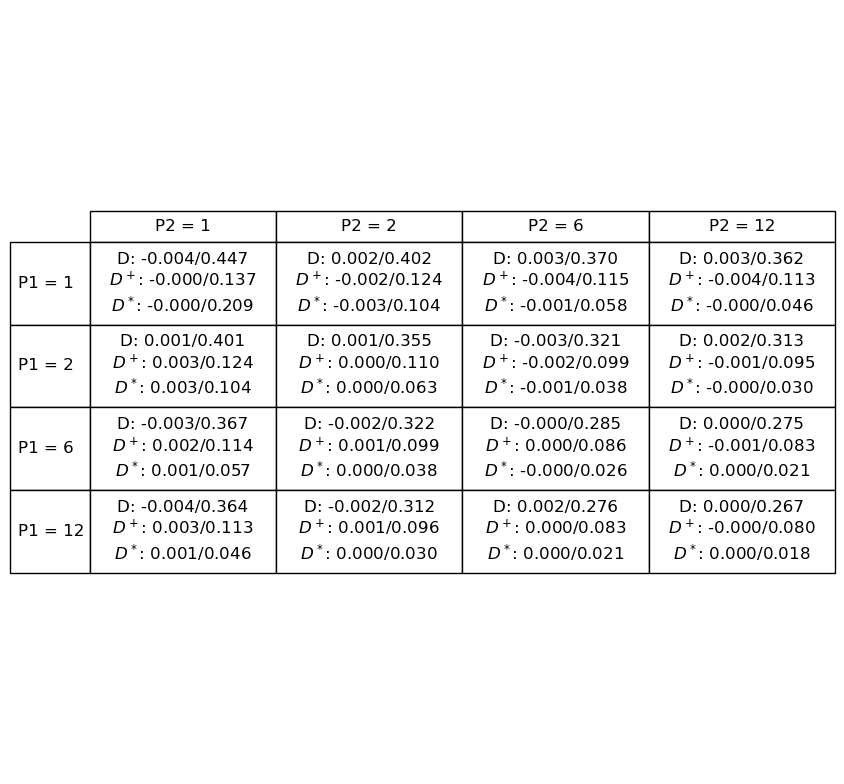

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

cell_text = []
for p1 in range(4):
    row = []
    for p2 in range(4):
        dNull = load_null(f'results/n/P1_{P1[p1]}_P2_{P2[p2]}/noIntro/d_null.txt')
        dplusNull = load_null(f'results/n/P1_{P1[p1]}_P2_{P2[p2]}/noIntro/dplus_null.txt')
        dstarNull = load_null(f'results/n/P1_{P1[p1]}_P2_{P2[p2]}/noIntro/dstar_null.txt')

        means = [
            np.mean(dNull),
            np.mean(dplusNull),
            np.mean(dstarNull)
        ]
        stds = [
            np.std(dNull),
            np.std(dplusNull),
            np.std(dstarNull)
        ]
        text = (
            f"D: {means[0]:.3f}/{stds[0]:.3f}\n"
            f"$D^+$: {means[1]:.3f}/{stds[1]:.3f}\n"
            f"$D^*$: {means[2]:.3f}/{stds[2]:.3f}"
        )
        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P1 = {x}" for x in P1],
    colLabels=[f"P2 = {x}" for x in P2],
    cellLoc='center',
    loc='center'
)
for j in range(4):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 4)
plt.tight_layout()
plt.savefig("null_n_table.png", dpi=300)
plt.show()
        

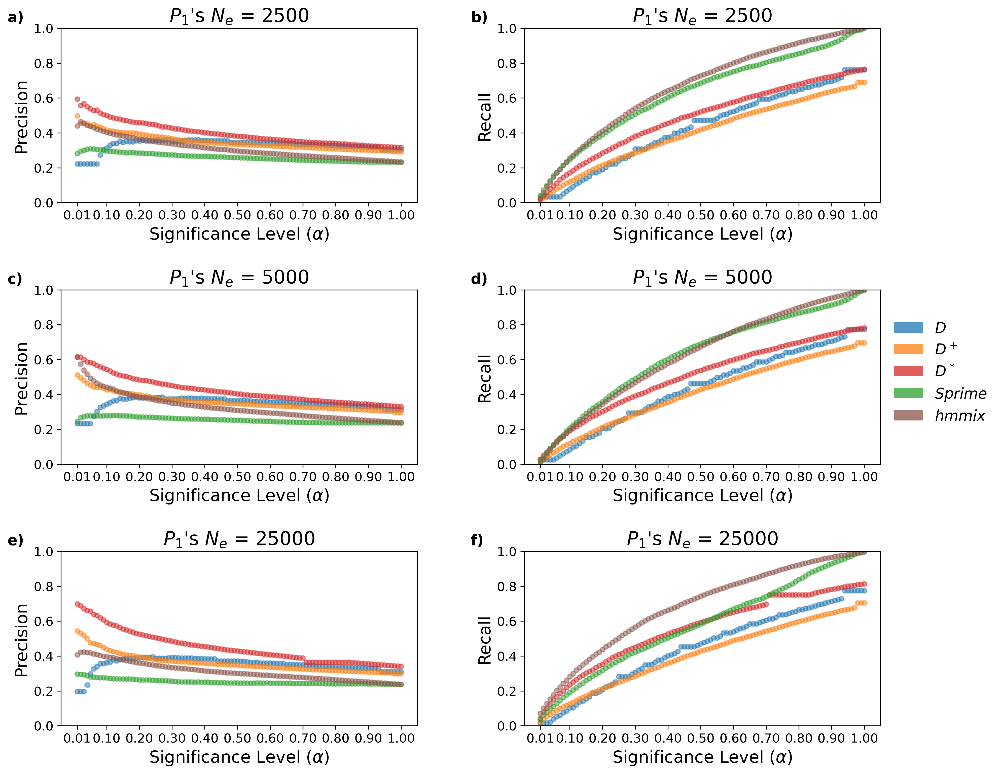

In [14]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 12), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for i, N in enumerate([2500, 5000, 25000]):
    cond_wind = drift[i]['wind_thresh'] == 0.1
    cond_d = drift[i]['stat'] == 'd'
    cond_dplus = drift[i]['stat'] == 'dplus'
    cond_dstar = drift[i]['stat'] == 'dstar'
    cond_sprime = drift[i]['stat'] == 'Sprime'
    cond_hmmix = drift[i]['stat'] == 'hmmix'
    axes[i][0].scatter(
        xs, drift[i][cond_wind & cond_d]['precision'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i][cond_wind & cond_dplus]['precision'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i][cond_wind & cond_dstar]['precision'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i][cond_wind & cond_sprime]['precision'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i][cond_wind & cond_hmmix]['precision'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i][cond_wind & cond_d]['recall'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i][cond_wind & cond_dplus]['recall'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i][cond_wind & cond_dstar]['recall'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i][cond_wind & cond_sprime]['recall'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i][cond_wind & cond_hmmix]['recall'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][0].set_title(r"$P_1$'s $N_e$ = {0}".format(N))
    axes[i][0].set_ylabel('Precision')
    axes[i][0].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][0].set_ylim(0, 1)
    axes[i][0].set_xticks(x_ticks)
    axes[i][1].set_title(r"$P_1$'s $N_e$ = {0}".format(N))
    axes[i][1].set_ylabel('Recall')
    axes[i][1].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][1].set_ylim(0, 1)
    axes[i][1].set_xticks(x_ticks)

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
    Patch(facecolor='tab:green', alpha=0.75, label=r'$Sprime$'),
    Patch(facecolor='tab:brown', alpha=0.75, label=r'$hmmix$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("drift_p1.png", dpi=300)
plt.show()

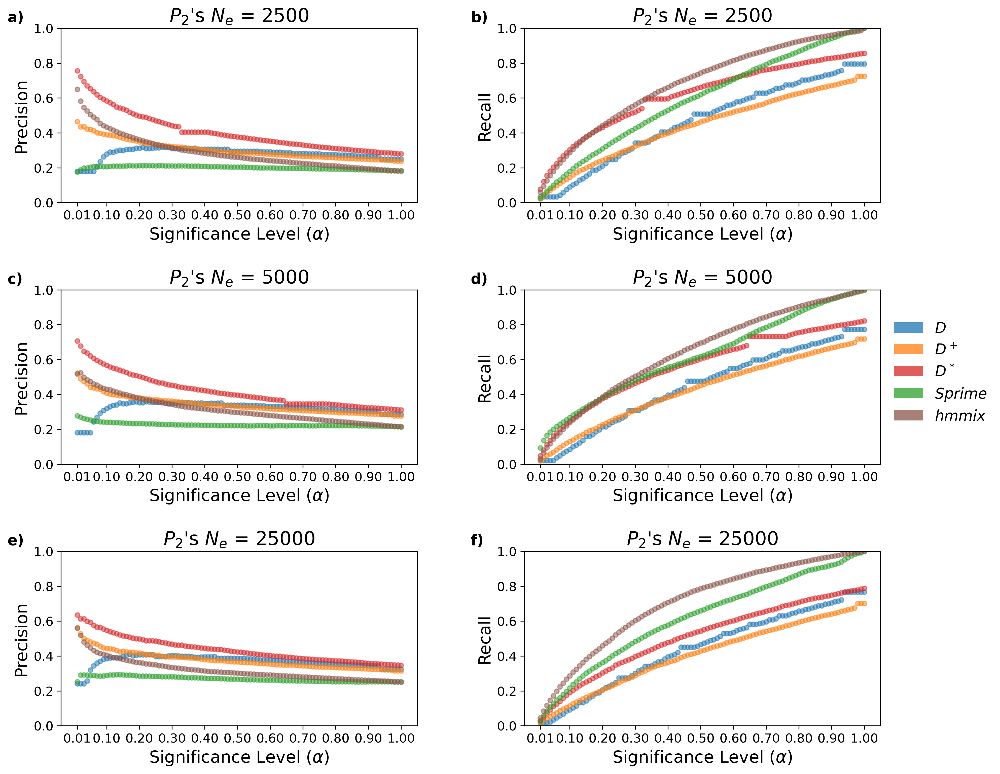

In [15]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 12), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for i, N in enumerate([2500, 5000, 25000]):
    cond_wind = drift[i+3]['wind_thresh'] == 0.1
    cond_d = drift[i+3]['stat'] == 'd'
    cond_dplus = drift[i+3]['stat'] == 'dplus'
    cond_dstar = drift[i+3]['stat'] == 'dstar'
    cond_sprime = drift[i+3]['stat'] == 'Sprime'
    cond_hmmix = drift[i+3]['stat'] == 'hmmix'
    axes[i][0].scatter(
        xs, drift[i+3][cond_wind & cond_d]['precision'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i+3][cond_wind & cond_dplus]['precision'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i+3][cond_wind & cond_dstar]['precision'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i+3][cond_wind & cond_sprime]['precision'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, drift[i+3][cond_wind & cond_hmmix]['precision'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i+3][cond_wind & cond_d]['recall'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i+3][cond_wind & cond_dplus]['recall'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i+3][cond_wind & cond_dstar]['recall'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i+3][cond_wind & cond_sprime]['recall'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, drift[i+3][cond_wind & cond_hmmix]['recall'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][0].set_title(r"$P_2$'s $N_e$ = {0}".format(N))
    axes[i][0].set_ylabel('Precision')
    axes[i][0].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][0].set_ylim(0, 1)
    axes[i][0].set_xticks(x_ticks)
    axes[i][1].set_title(r"$P_2$'s $N_e$ = {0}".format(N))
    axes[i][1].set_ylabel('Recall')
    axes[i][1].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][1].set_ylim(0, 1)
    axes[i][1].set_xticks(x_ticks)

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
    Patch(facecolor='tab:green', alpha=0.75, label=r'$Sprime$'),
    Patch(facecolor='tab:brown', alpha=0.75, label=r'$hmmix$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("drift_p2.png", dpi=300)
plt.show()

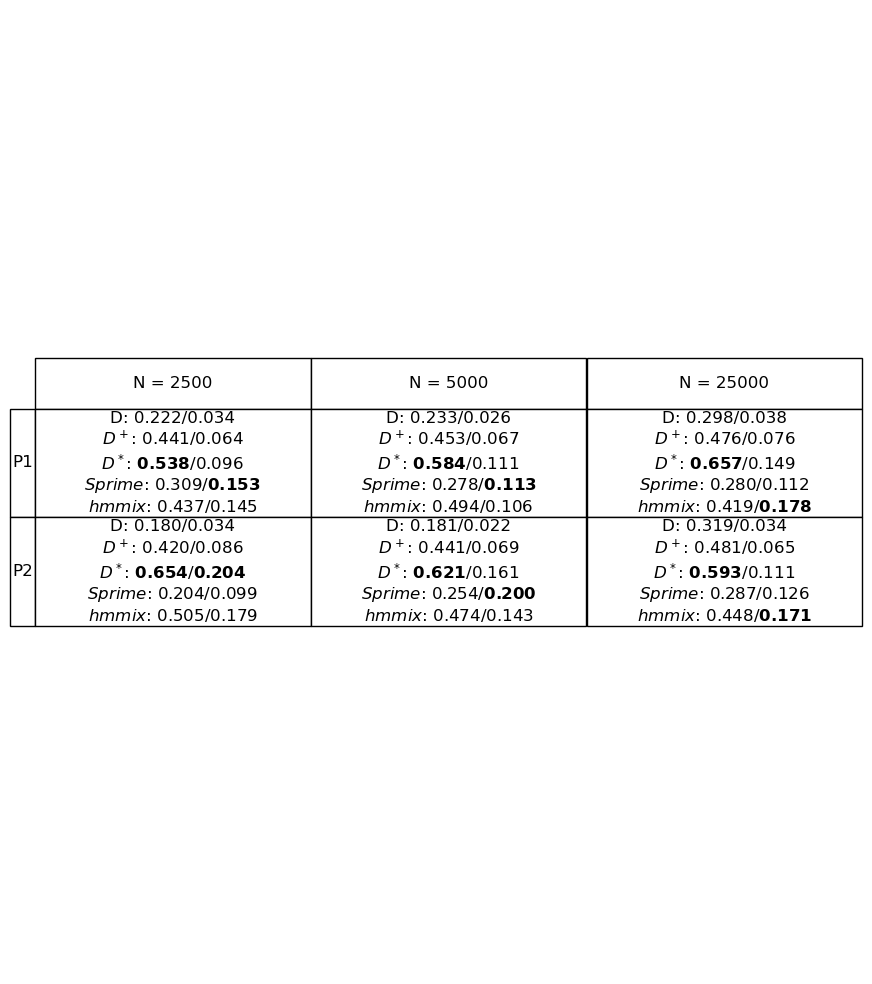

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')

def format_max(values):
    """Format values to 3 decimals, bolding the maximum."""
    max_idx = np.nanargmax(values)

    formatted = []

    for i, value in enumerate(values):
        if i == max_idx:
            formatted.append(f"$\\mathbf{{{value:.3f}}}$")
        else:
            formatted.append(f"{value:.3f}")

    return formatted


cell_text = []
for P in range(2):
    row = []
    for i, N in enumerate([2500, 5000, 25000]):
        cond_wind = drift[P * 3 + i]['wind_thresh'] == 0.1
        cond_d = drift[P * 3 + i]['stat'] == 'd'
        cond_dplus = drift[P * 3 + i]['stat'] == 'dplus'
        cond_dstar = drift[P * 3 + i]['stat'] == 'dstar'
        cond_sprime = drift[P * 3 + i]['stat'] == 'Sprime'
        cond_hmmix = drift[P * 3 + i]['stat'] == 'hmmix'
        d_prec = drift[P * 3 + i][cond_wind & cond_d]['precision'].values[4]
        d_recall = drift[P * 3 + i][cond_wind & cond_d]['recall'].values[4]
        dplus_prec = drift[P * 3 + i][cond_wind & cond_dplus]['precision'].values[4]
        dplus_recall = drift[P * 3 + i][cond_wind & cond_dplus]['recall'].values[4]
        dstar_prec = drift[P * 3 + i][cond_wind & cond_dstar]['precision'].values[4]
        dstar_recall = drift[P * 3 + i][cond_wind & cond_dstar]['recall'].values[4]
        sprime_prec = drift[P * 3 + i][cond_wind & cond_sprime]['precision'].values[4]
        sprime_recall = drift[P * 3 + i][cond_wind & cond_sprime]['recall'].values[4]
        hmmix_prec = drift[P * 3 + i][cond_wind & cond_hmmix]['precision'].values[4]
        hmmix_recall = drift[P * 3 + i][cond_wind & cond_hmmix]['recall'].values[4]
        # Precision
        prec_values = [
            d_prec,
            dplus_prec,
            dstar_prec,
            sprime_prec,
            hmmix_prec
        ]
        
        d_prec, dplus_prec, dstar_prec, sprime_prec, hmmix_prec = format_max(prec_values)
        
        
        # Recall
        recall_values = [
            d_recall,
            dplus_recall,
            dstar_recall,
            sprime_recall,
            hmmix_recall
        ]
        
        d_recall, dplus_recall, dstar_recall, sprime_recall, hmmix_recall = format_max(recall_values)
        text = (
            f"D: {d_prec}/{d_recall}\n"
            f"$D^+$: {dplus_prec}/{dplus_recall}\n"
            f"$D^*$: {dstar_prec}/{dstar_recall}\n"
            f"$Sprime$: {sprime_prec}/{sprime_recall}\n"
            f"$hmmix$: {hmmix_prec}/{hmmix_recall}"
        )

        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P{x + 1}" for x in [0, 1]],
    colLabels=[f"N = {x}" for x in [2500, 5000, 25000]],
    cellLoc='center',
    loc='center'
)
for j in range(3):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 5.2)
plt.tight_layout()
plt.savefig("drift_table.png", dpi=300)
plt.show()


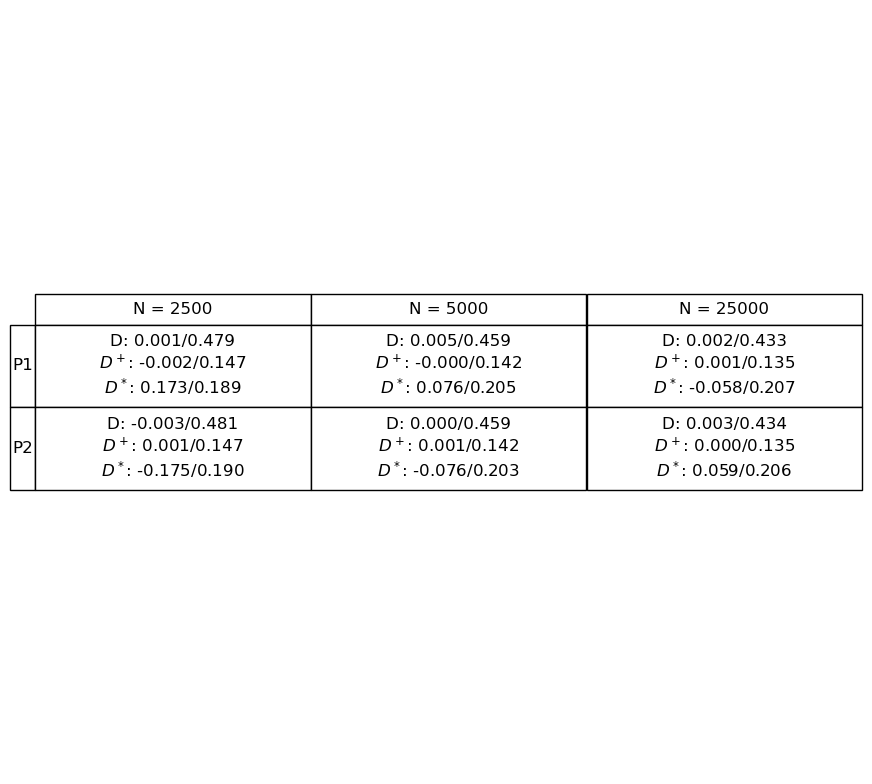

<Figure size 640x480 with 0 Axes>

In [17]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

cell_text = []
for P in range(2):
    row = []
    for i, N in enumerate([2500, 5000, 25000]):
        dNull = load_null(f'results/drift/scenario{P * 3 + i + 1}/noIntro/d_null.txt')
        dplusNull = load_null(f'results/drift/scenario{P * 3 + i + 1}/noIntro/dplus_null.txt')
        dstarNull = load_null(f'results/drift/scenario{P * 3 + i + 1}/noIntro/dstar_null.txt')

        means = [
            np.mean(dNull),
            np.mean(dplusNull),
            np.mean(dstarNull)
        ]
        stds = [
            np.std(dNull),
            np.std(dplusNull),
            np.std(dstarNull)
        ]
        text = (
            f"D: {means[0]:.3f}/{stds[0]:.3f}\n"
            f"$D^+$: {means[1]:.3f}/{stds[1]:.3f}\n"
            f"$D^*$: {means[2]:.3f}/{stds[2]:.3f}"
        )
        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P{x + 1}" for x in [0, 1]],
    colLabels=[f"N = {x}" for x in [2500, 5000, 25000]],
    cellLoc='center',
    loc='center'
)
for j in range(3):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 4)
plt.tight_layout()
plt.show()
plt.savefig("null_drift_table.png", dpi=300)
        

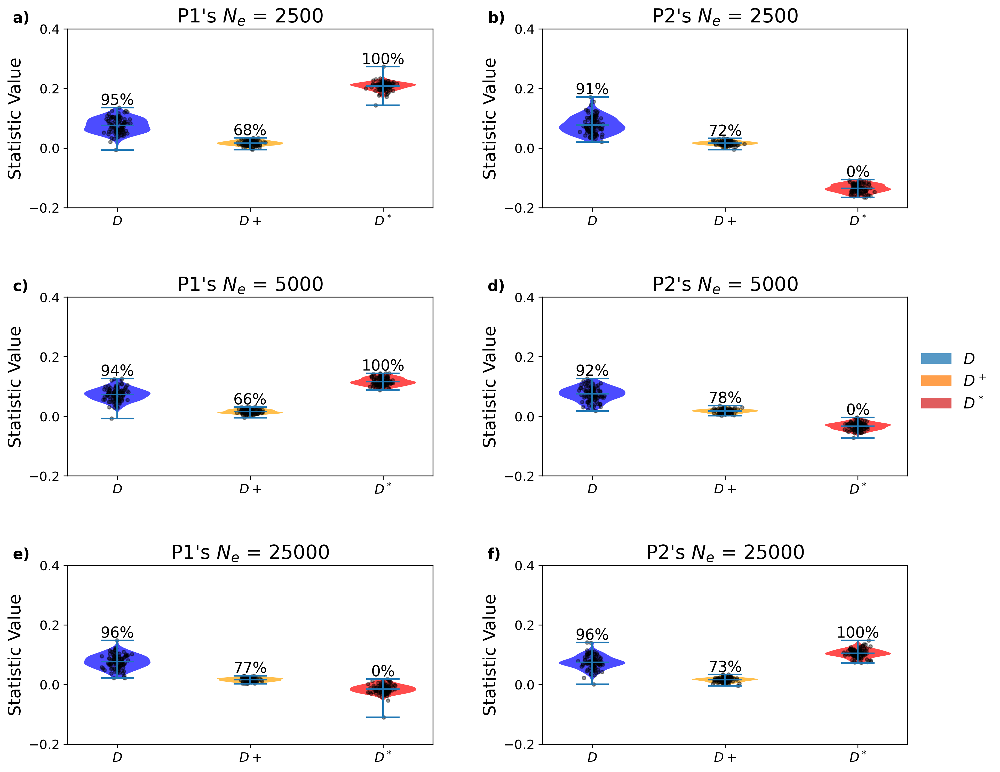

In [18]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 12), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for P in range(2):
    for s in range(1, 4):
        global_df = pd.read_csv(f'results/drift/scenario{3 * P + s}/intro/global.tsv', sep='\t')
        positions = [1, 2, 3]
        violins = axes[s - 1][P].violinplot([global_df['D'], global_df['D+'], global_df['D*']], positions=positions, showextrema=True, showmeans = True)
        # Color
        colors = ['blue', 'orange', 'red']
        for body, color in zip(violins['bodies'], colors):
            body.set_facecolor(color)
            body.set_alpha(0.7)
        
        # Overlay points with jitter
        for i, d in enumerate([global_df['D'], global_df['D+'], global_df['D*']]):
            x = np.random.normal(positions[i], 0.04, size=len(d))
            axes[s - 1][P].scatter(x, d, s=10, alpha=0.4, color='black')
        # Add power labels.
        count = np.sum(global_df.iloc[:,4] < 0.05)
        axes[s - 1][P].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,5] < 0.05)
        axes[s - 1][P].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,6] < 0.05)
        axes[s - 1][P].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        axes[s - 1][P].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
        axes[s - 1][P].set_ylabel('Statistic Value')
        axes[s - 1][P].set_ylim((-0.2, 0.4))
        axes[s - 1][P].set_title(f"P{P+1}'s $N_e$ = {[2500, 5000, 25000][s - 1]}")

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("drift_global.png", dpi=300)
plt.show()

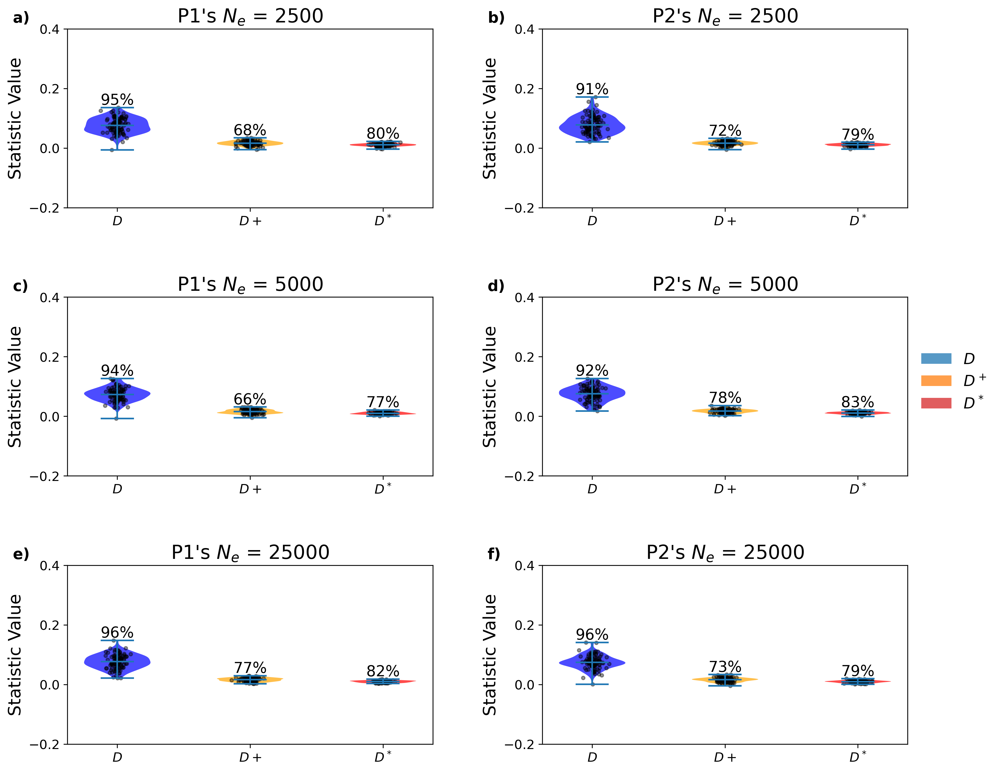

In [19]:
fig, axes = plt.subplots(
    3, 2, figsize=(14, 12), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for P in range(2):
    for s in range(1, 4):
        global_df = pd.read_csv(f'results/drift/scenario{3 * P + s}/intro/g1/global.tsv', sep='\t')
        positions = [1, 2, 3]
        violins = axes[s - 1][P].violinplot([global_df['D'], global_df['D+'], global_df['D*']], positions=positions, showextrema=True, showmeans = True)
        # Color
        colors = ['blue', 'orange', 'red']
        for body, color in zip(violins['bodies'], colors):
            body.set_facecolor(color)
            body.set_alpha(0.7)
        
        # Overlay points with jitter
        for i, d in enumerate([global_df['D'], global_df['D+'], global_df['D*']]):
            x = np.random.normal(positions[i], 0.04, size=len(d))
            axes[s - 1][P].scatter(x, d, s=10, alpha=0.4, color='black')
        # Add power labels.
        count = np.sum(global_df.iloc[:,4] < 0.05)
        axes[s - 1][P].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,5] < 0.05)
        axes[s - 1][P].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,6] < 0.05)
        axes[s - 1][P].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        axes[s - 1][P].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
        axes[s - 1][P].set_ylabel('Statistic Value')
        axes[s - 1][P].set_ylim((-0.2, 0.4))
        axes[s - 1][P].set_title(f"P{P+1}'s $N_e$ = {[2500, 5000, 25000][s - 1]}")

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("drift_g1_global.png", dpi=300)
plt.show()

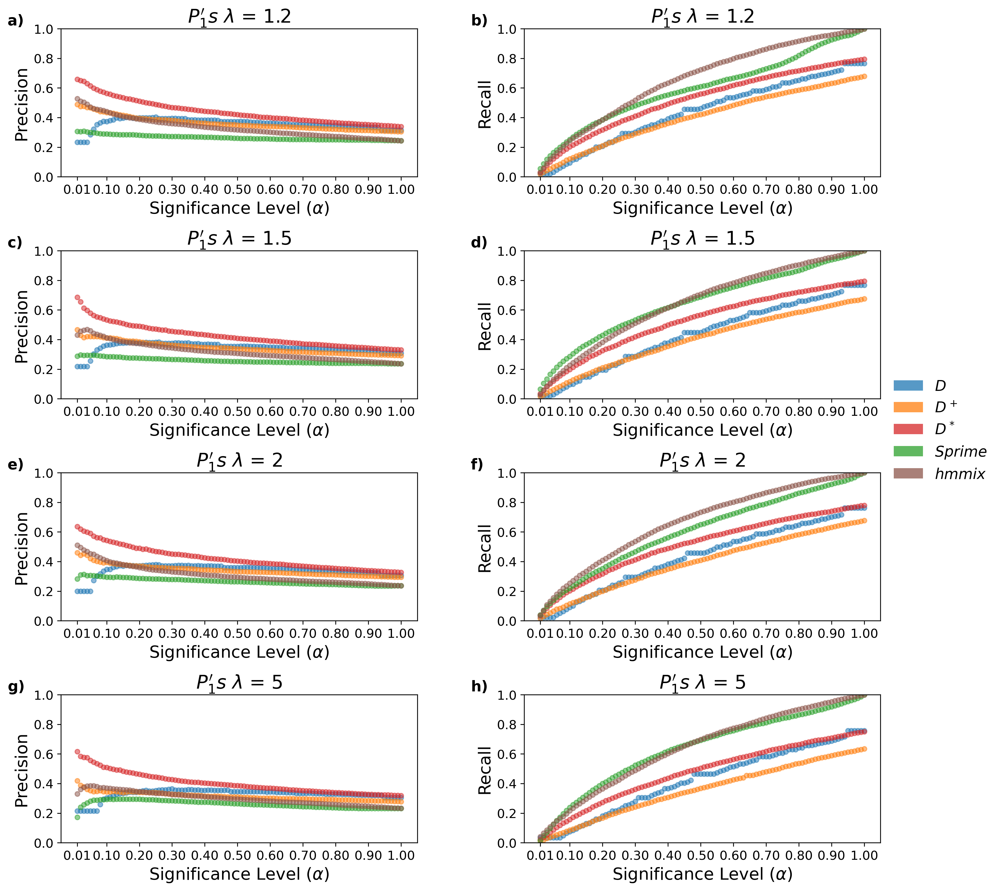

In [20]:
fig, axes = plt.subplots(
    4, 2, figsize=(14, 14), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for i, l in enumerate([1.2, 1.5, 2, 5]):
    cond_wind = molClock[i]['wind_thresh'] == 0.1
    cond_d = molClock[i]['stat'] == 'd'
    cond_dplus = molClock[i]['stat'] == 'dplus'
    cond_dstar = molClock[i]['stat'] == 'dstar'
    cond_sprime = molClock[i]['stat'] == 'Sprime'
    cond_hmmix = molClock[i]['stat'] == 'hmmix'
    axes[i][0].scatter(
        xs, molClock[i][cond_wind & cond_d]['precision'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i][cond_wind & cond_dplus]['precision'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i][cond_wind & cond_dstar]['precision'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i][cond_wind & cond_sprime]['precision'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i][cond_wind & cond_hmmix]['precision'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i][cond_wind & cond_d]['recall'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i][cond_wind & cond_dplus]['recall'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i][cond_wind & cond_dstar]['recall'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i][cond_wind & cond_sprime]['recall'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i][cond_wind & cond_hmmix]['recall'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][0].set_title(r"$P_1's$ $\lambda$ = {0}".format(l))
    axes[i][0].set_ylabel('Precision')
    axes[i][0].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][0].set_ylim(0, 1)
    axes[i][0].set_xticks(x_ticks)
    axes[i][1].set_title(r"$P_1's$ $\lambda$ = {0}".format(l))
    axes[i][1].set_ylabel('Recall')
    axes[i][1].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][1].set_ylim(0, 1)
    axes[i][1].set_xticks(x_ticks)

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
    Patch(facecolor='tab:green', alpha=0.75, label=r'$Sprime$'),
    Patch(facecolor='tab:brown', alpha=0.75, label=r'$hmmix$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("molClock_p1.png", dpi=300)
plt.show()

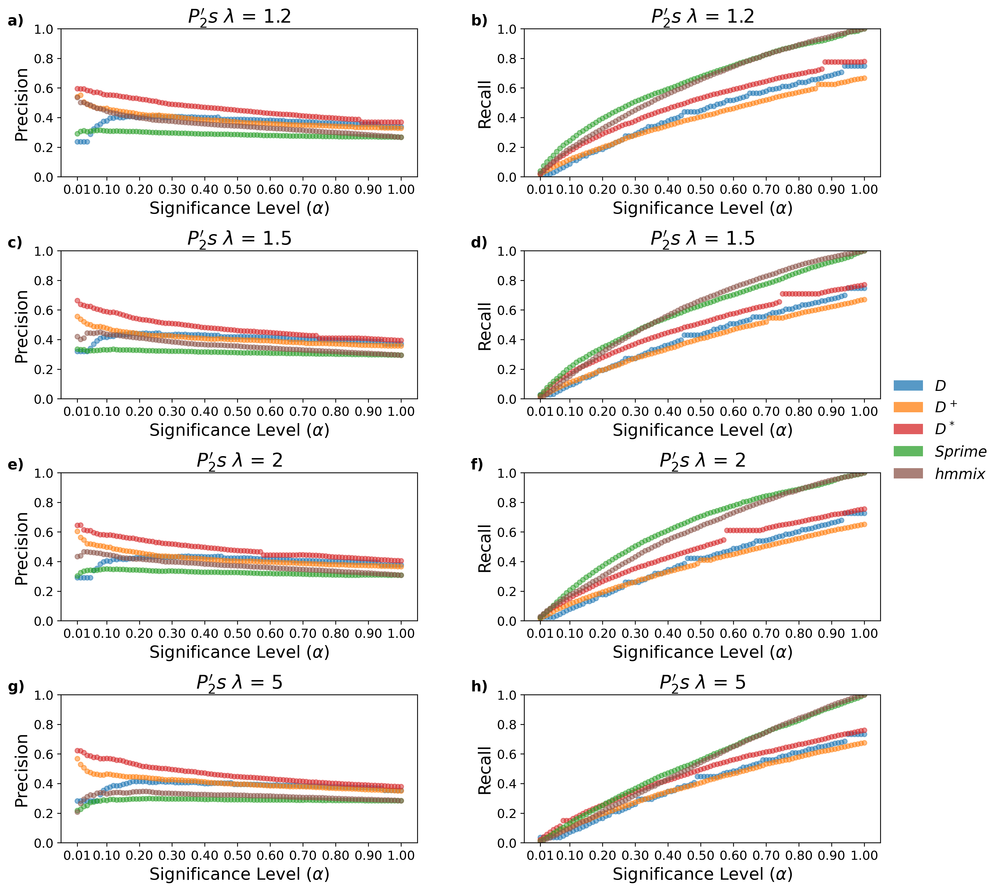

In [21]:
fig, axes = plt.subplots(
    4, 2, figsize=(14, 14), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for i, l in enumerate([1.2, 1.5, 2, 5]):
    cond_wind = molClock[i+4]['wind_thresh'] == 0.1
    cond_d = molClock[i+4]['stat'] == 'd'
    cond_dplus = molClock[i+4]['stat'] == 'dplus'
    cond_dstar = molClock[i+4]['stat'] == 'dstar'
    cond_sprime = molClock[i+4]['stat'] == 'Sprime'
    cond_hmmix = molClock[i+4]['stat'] == 'hmmix'
    axes[i][0].scatter(
        xs, molClock[i+4][cond_wind & cond_d]['precision'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i+4][cond_wind & cond_dplus]['precision'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i+4][cond_wind & cond_dstar]['precision'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i+4][cond_wind & cond_sprime]['precision'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, molClock[i+4][cond_wind & cond_hmmix]['precision'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i+4][cond_wind & cond_d]['recall'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i+4][cond_wind & cond_dplus]['recall'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i+4][cond_wind & cond_dstar]['recall'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i+4][cond_wind & cond_sprime]['recall'].values,
        marker='o', s=20, color='tab:green', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, molClock[i+4][cond_wind & cond_hmmix]['recall'].values,
        marker='o', s=20, color='tab:brown', alpha=0.5,
    )
    axes[i][0].set_title(r"$P_2's$ $\lambda$ = {0}".format(l))
    axes[i][0].set_ylabel('Precision')
    axes[i][0].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][0].set_ylim(0, 1)
    axes[i][0].set_xticks(x_ticks)
    axes[i][1].set_title(r"$P_2's$ $\lambda$ = {0}".format(l))
    axes[i][1].set_ylabel('Recall')
    axes[i][1].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][1].set_ylim(0, 1)
    axes[i][1].set_xticks(x_ticks)

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
    Patch(facecolor='tab:green', alpha=0.75, label=r'$Sprime$'),
    Patch(facecolor='tab:brown', alpha=0.75, label=r'$hmmix$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("molClock_p2.png", dpi=300)
plt.show()

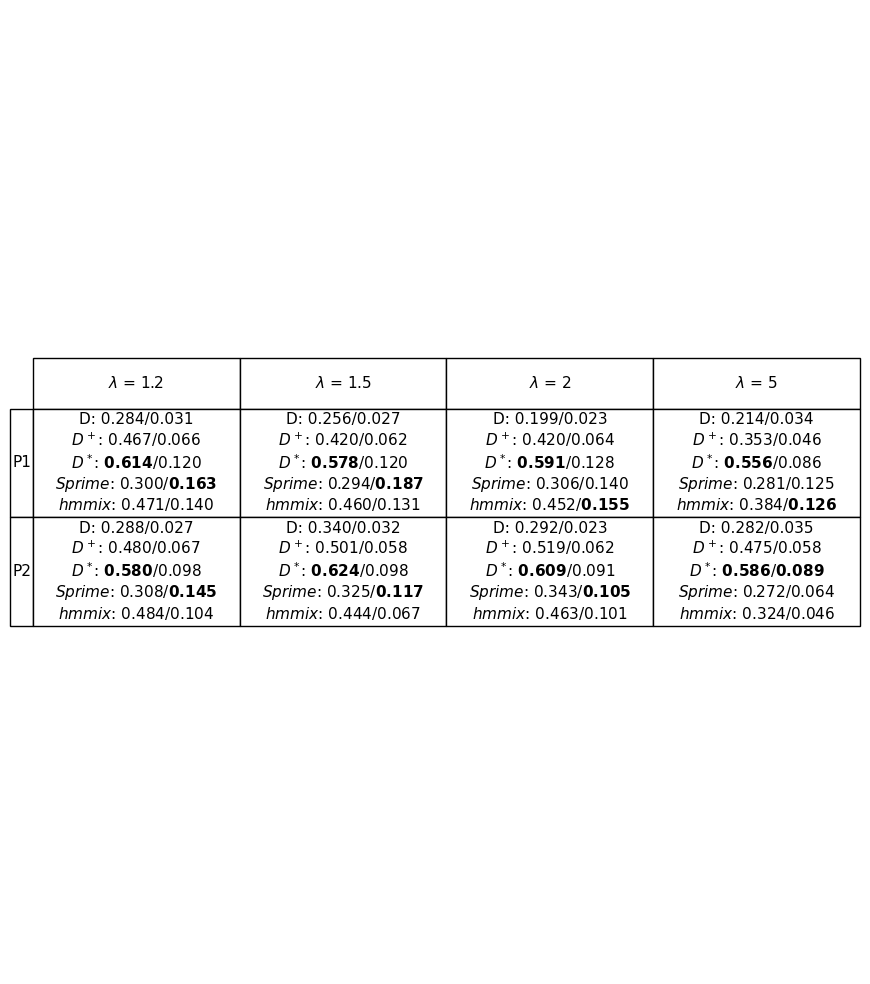

In [21]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')

def format_max(values):
    """Format values to 3 decimals, bolding the maximum."""
    max_idx = np.nanargmax(values)

    formatted = []

    for i, value in enumerate(values):
        if i == max_idx:
            formatted.append(f"$\\mathbf{{{value:.3f}}}$")
        else:
            formatted.append(f"{value:.3f}")

    return formatted


cell_text = []
for P in range(2):
    row = []
    for i, l in enumerate([1.2, 1.5, 2, 5]):
        cond_wind = molClock[P * 4 + i]['wind_thresh'] == 0.1
        cond_d = molClock[P * 4 + i]['stat'] == 'd'
        cond_dplus = molClock[P * 4 + i]['stat'] == 'dplus'
        cond_dstar = molClock[P * 4 + i]['stat'] == 'dstar'
        cond_sprime = molClock[P * 4 + i]['stat'] == 'Sprime'
        cond_hmmix = molClock[P * 4 + i]['stat'] == 'hmmix'
        d_prec = molClock[P * 4 + i][cond_wind & cond_d]['precision'].values[4]
        d_recall = molClock[P * 4 + i][cond_wind & cond_d]['recall'].values[4]
        dplus_prec = molClock[P * 4 + i][cond_wind & cond_dplus]['precision'].values[4]
        dplus_recall = molClock[P * 4 + i][cond_wind & cond_dplus]['recall'].values[4]
        dstar_prec = molClock[P * 4 + i][cond_wind & cond_dstar]['precision'].values[4]
        dstar_recall = molClock[P * 4 + i][cond_wind & cond_dstar]['recall'].values[4]
        sprime_prec = molClock[P * 4 + i][cond_wind & cond_sprime]['precision'].values[4]
        sprime_recall = molClock[P * 4 + i][cond_wind & cond_sprime]['recall'].values[4]
        hmmix_prec = molClock[P * 4 + i][cond_wind & cond_hmmix]['precision'].values[4]
        hmmix_recall = molClock[P * 4 + i][cond_wind & cond_hmmix]['recall'].values[4]
        # Precision
        prec_values = [
            d_prec,
            dplus_prec,
            dstar_prec,
            sprime_prec,
            hmmix_prec
        ]
        
        d_prec, dplus_prec, dstar_prec, sprime_prec, hmmix_prec = format_max(prec_values)
        
        
        # Recall
        recall_values = [
            d_recall,
            dplus_recall,
            dstar_recall,
            sprime_recall,
            hmmix_recall
        ]
        
        d_recall, dplus_recall, dstar_recall, sprime_recall, hmmix_recall = format_max(recall_values)
        text = (
            f"D: {d_prec}/{d_recall}\n"
            f"$D^+$: {dplus_prec}/{dplus_recall}\n"
            f"$D^*$: {dstar_prec}/{dstar_recall}\n"
            f"$Sprime$: {sprime_prec}/{sprime_recall}\n"
            f"$hmmix$: {hmmix_prec}/{hmmix_recall}"
        )

        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P{x + 1}" for x in [0, 1]],
    colLabels=[r"$\lambda$ = 1.2", r"$\lambda$ = 1.5", r"$\lambda$ = 2", r"$\lambda$ = 5"],
    cellLoc='center',
    loc='center'
)
for j in range(4):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 5.2)
plt.tight_layout()
plt.savefig("molClock_table.png", dpi=300)
plt.show()


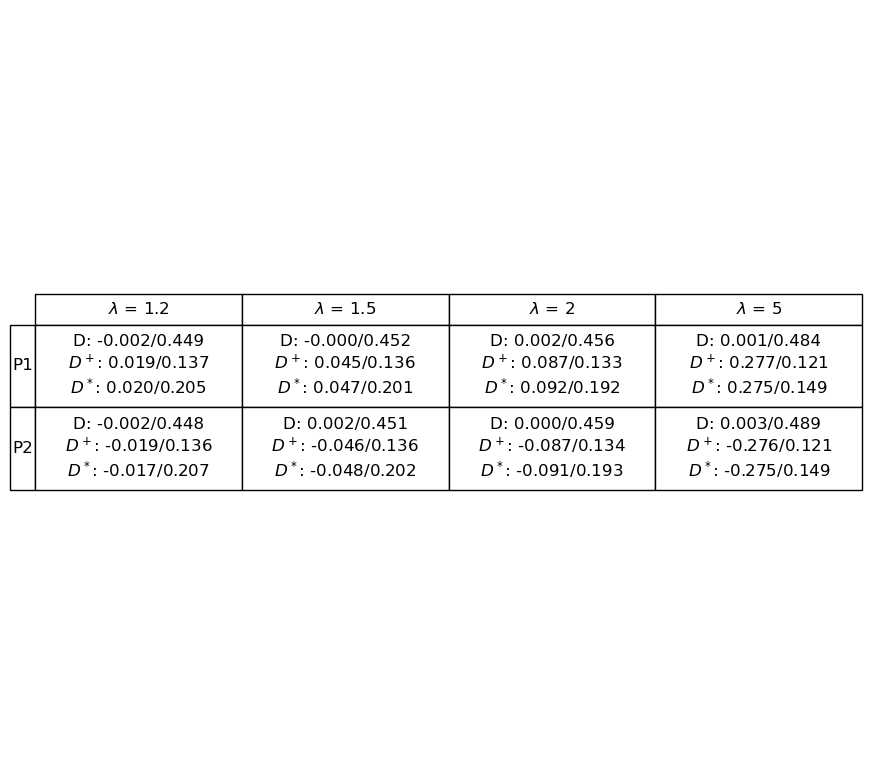

<Figure size 640x480 with 0 Axes>

In [23]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

cell_text = []
for P in range(2):
    row = []
    for i, l in enumerate([1.2, 1.5, 2, 5]):
        dNull = load_null(f'results/molClock/scenario{P * 4 + i + 1}/noIntro/d_null.txt')
        dplusNull = load_null(f'results/molClock/scenario{P * 4 + i + 1}/noIntro/dplus_null.txt')
        dstarNull = load_null(f'results/molClock/scenario{P * 4 + i + 1}/noIntro/dstar_null.txt')

        means = [
            np.mean(dNull),
            np.mean(dplusNull),
            np.mean(dstarNull)
        ]
        stds = [
            np.std(dNull),
            np.std(dplusNull),
            np.std(dstarNull)
        ]
        text = (
            f"D: {means[0]:.3f}/{stds[0]:.3f}\n"
            f"$D^+$: {means[1]:.3f}/{stds[1]:.3f}\n"
            f"$D^*$: {means[2]:.3f}/{stds[2]:.3f}"
        )
        row.append(text)

    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    rowLabels=[f"P{x + 1}" for x in [0, 1]],
    colLabels=[r"$\lambda$ = 1.2", r"$\lambda$ = 1.5", r"$\lambda$ = 2", r"$\lambda$ = 5"],
    cellLoc='center',
    loc='center'
)
for j in range(4):
    table[(0, j)].set_height(0.01)
table.scale(1.5, 4)
plt.tight_layout()
plt.show()
plt.savefig("null_molClock_table.png", dpi=300)
        

<>:34: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\l'
/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_11040/3236743963.py:34: SyntaxWarning: invalid escape sequence '\l'
  axes[s - 1][P].set_title(f"P{P+1}'s $\lambda$ = {[1.2, 1.5, 2, 5][s - 1]}")


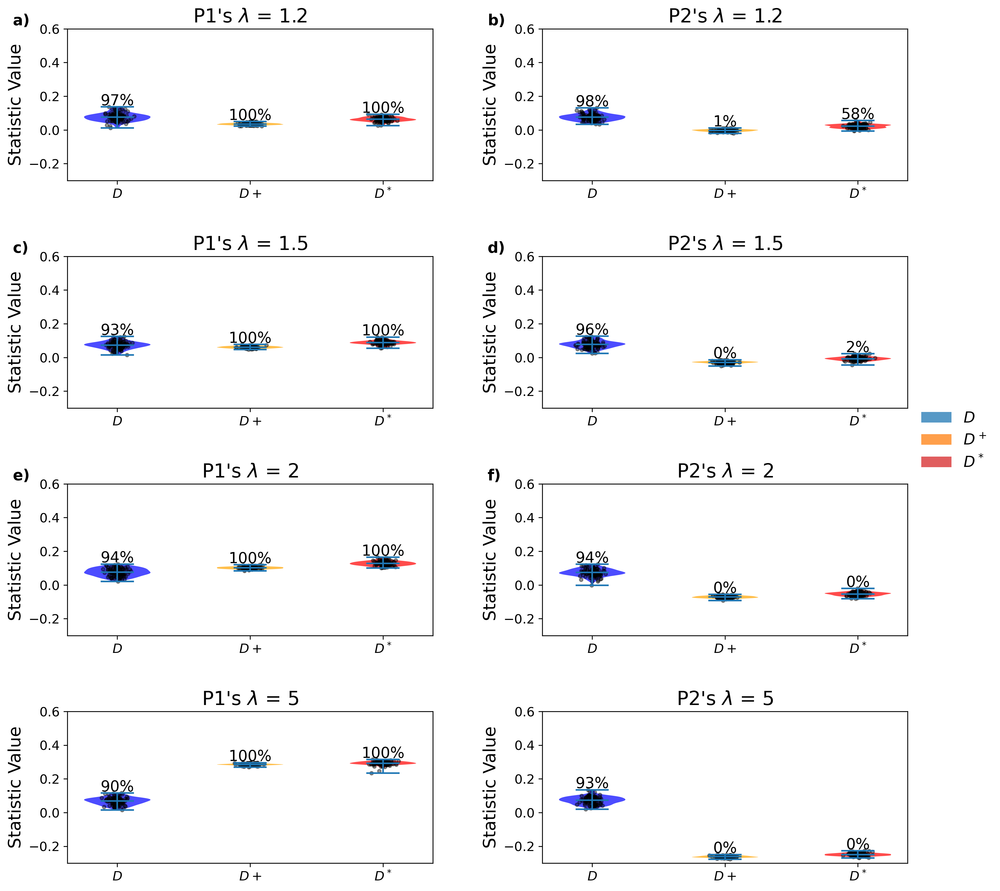

In [26]:
fig, axes = plt.subplots(
    4, 2, figsize=(14, 14), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for P in range(2):
    for s in range(1, 5):
        global_df = pd.read_csv(f'results/molClock/scenario{4 * P + s}/intro/global.tsv', sep='\t')
        positions = [1, 2, 3]
        violins = axes[s - 1][P].violinplot([global_df['D'], global_df['D+'], global_df['D*']], positions=positions, showextrema=True, showmeans = True)
        # Color
        colors = ['blue', 'orange', 'red']
        for body, color in zip(violins['bodies'], colors):
            body.set_facecolor(color)
            body.set_alpha(0.7)
        
        # Overlay points with jitter
        for i, d in enumerate([global_df['D'], global_df['D+'], global_df['D*']]):
            x = np.random.normal(positions[i], 0.04, size=len(d))
            axes[s - 1][P].scatter(x, d, s=10, alpha=0.4, color='black')
        # Add power labels.
        count = np.sum(global_df.iloc[:,4] < 0.05)
        axes[s - 1][P].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,5] < 0.05)
        axes[s - 1][P].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,6] < 0.05)
        axes[s - 1][P].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        axes[s - 1][P].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
        axes[s - 1][P].set_ylabel('Statistic Value')
        axes[s - 1][P].set_ylim((-0.3, 0.6))
        axes[s - 1][P].set_title(f"P{P+1}'s $\lambda$ = {[1.2, 1.5, 2, 5][s - 1]}")

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("molClock_global.png", dpi=300)
plt.show()

<>:34: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\l'
/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_11040/3996175757.py:34: SyntaxWarning: invalid escape sequence '\l'
  axes[s - 1][P].set_title(f"P{P+1}'s $\lambda$ = {[1.2, 1.5, 2, 5][s - 1]}")


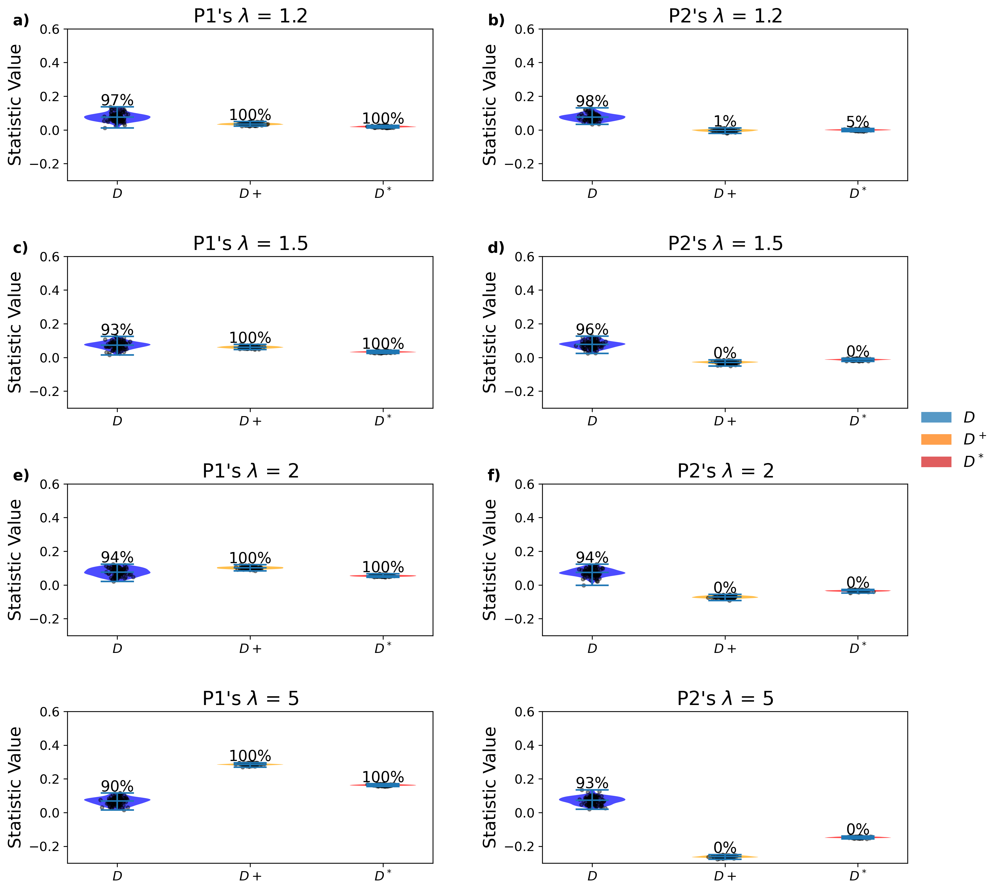

In [27]:
fig, axes = plt.subplots(
    4, 2, figsize=(14, 14), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for P in range(2):
    for s in range(1, 5):
        global_df = pd.read_csv(f'results/molClock/scenario{4 * P + s}/intro/g1/global.tsv', sep='\t')
        positions = [1, 2, 3]
        violins = axes[s - 1][P].violinplot([global_df['D'], global_df['D+'], global_df['D*']], positions=positions, showextrema=True, showmeans = True)
        # Color
        colors = ['blue', 'orange', 'red']
        for body, color in zip(violins['bodies'], colors):
            body.set_facecolor(color)
            body.set_alpha(0.7)
        
        # Overlay points with jitter
        for i, d in enumerate([global_df['D'], global_df['D+'], global_df['D*']]):
            x = np.random.normal(positions[i], 0.04, size=len(d))
            axes[s - 1][P].scatter(x, d, s=10, alpha=0.4, color='black')
        # Add power labels.
        count = np.sum(global_df.iloc[:,4] < 0.05)
        axes[s - 1][P].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,5] < 0.05)
        axes[s - 1][P].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        count = np.sum(global_df.iloc[:,6] < 0.05)
        axes[s - 1][P].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
            ha='center', fontsize=14)
        axes[s - 1][P].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
        axes[s - 1][P].set_ylabel('Statistic Value')
        axes[s - 1][P].set_ylim((-0.3, 0.6))
        axes[s - 1][P].set_title(f"P{P+1}'s $\lambda$ = {[1.2, 1.5, 2, 5][s - 1]}")

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("molClock_g1_global.png", dpi=300)
plt.show()

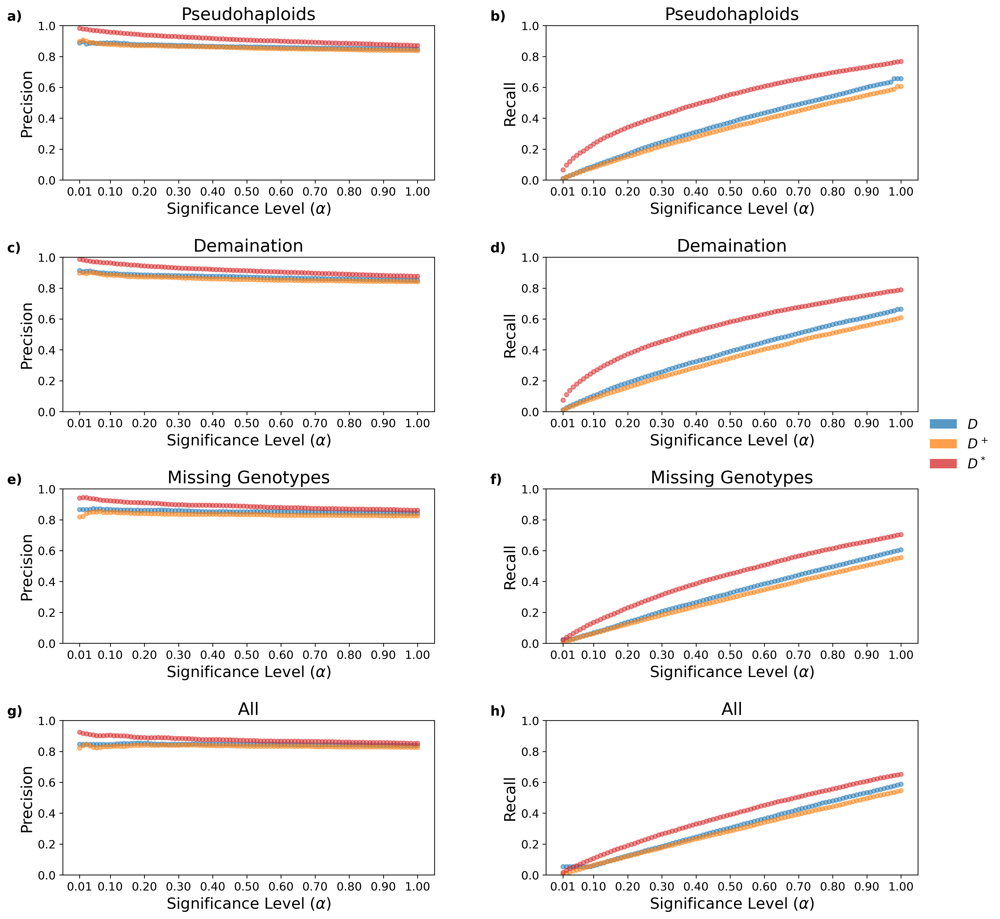

In [28]:
fig, axes = plt.subplots(
    4, 2, figsize=(16, 16), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for i, a in enumerate(['pseudo_hap', 'deamin', 'missing', 'all']):
    cond_wind = adna[a]['wind_thresh'] == 0.1
    cond_d = adna[a]['stat'] == 'd'
    cond_dplus = adna[a]['stat'] == 'dplus'
    cond_dstar = adna[a]['stat'] == 'dstar'
    axes[i][0].scatter(
        xs, adna[a][cond_wind & cond_d]['precision'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, adna[a][cond_wind & cond_dplus]['precision'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][0].scatter(
        xs, adna[a][cond_wind & cond_dstar]['precision'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, adna[a][cond_wind & cond_d]['recall'].values,
        marker='o', s=20, color='tab:blue', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, adna[a][cond_wind & cond_dplus]['recall'].values,
        marker='o', s=20, color='tab:orange', alpha=0.5,
    )
    axes[i][1].scatter(
        xs, adna[a][cond_wind & cond_dstar]['recall'].values,
        marker='o', s=20, color='tab:red', alpha=0.5,
    )
    axes[i][0].set_title(f"{['Pseudohaploids', 'Demaination', 'Missing Genotypes', 'All'][i]}")
    axes[i][0].set_ylabel('Precision')
    axes[i][0].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][0].set_ylim(0, 1)
    axes[i][0].set_xticks(x_ticks)
    axes[i][1].set_title(f"{['Pseudohaploids', 'Demaination', 'Missing Genotypes', 'All'][i]}")
    axes[i][1].set_ylabel('Recall')
    axes[i][1].set_xlabel(r'Significance Level ($\alpha$)')
    axes[i][1].set_ylim(0, 1)
    axes[i][1].set_xticks(x_ticks)

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("adna.png", dpi=300)
plt.show()

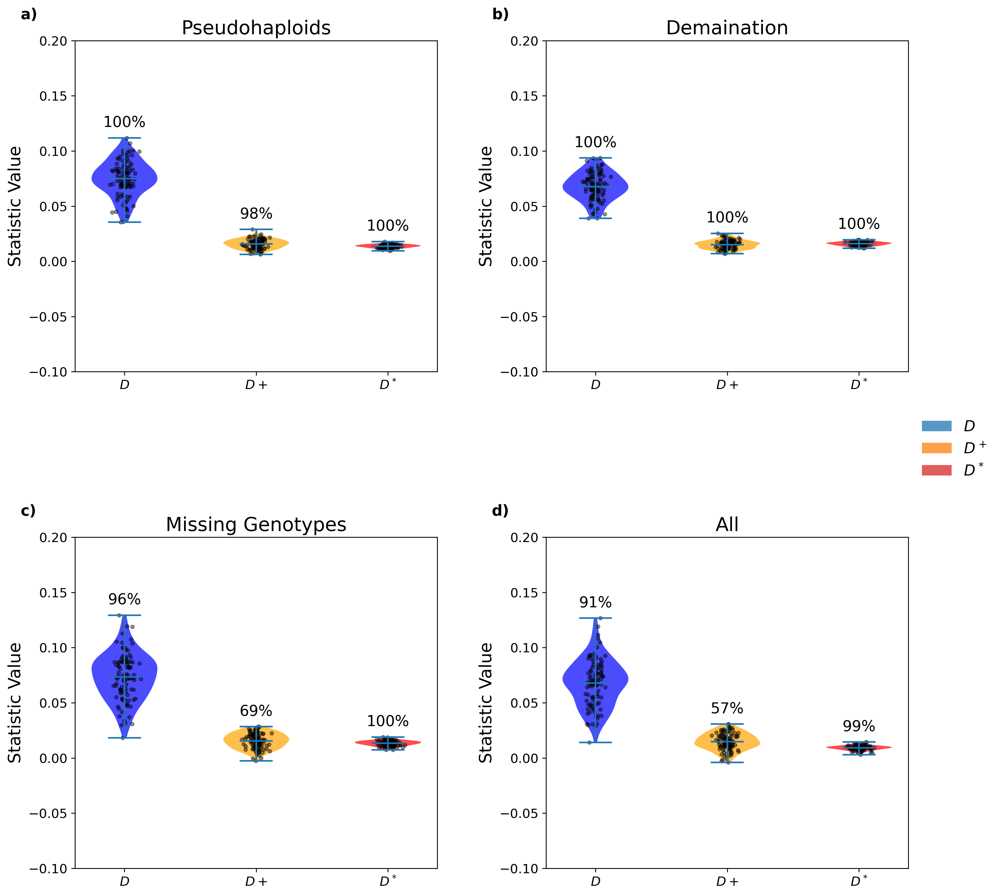

In [29]:
fig, axes = plt.subplots(
    2, 2, figsize=(14, 14), dpi=300.0,
    sharex=False, sharey=False, facecolor='white'
)

for i, a in enumerate(['pseudo_hap', 'deamin', 'missing', 'all']):
    global_df = pd.read_csv(f'results/adna/{a}/intro/global.tsv', sep='\t')
    positions = [1, 2, 3]
    violins = axes[i // 2][i % 2].violinplot([global_df['D'], global_df['D+'], global_df['D*']], positions=positions, showextrema=True, showmeans = True)
    # Color
    colors = ['blue', 'orange', 'red']
    for body, color in zip(violins['bodies'], colors):
        body.set_facecolor(color)
        body.set_alpha(0.7)
    
    # Overlay points with jitter
    for j, d in enumerate([global_df['D'], global_df['D+'], global_df['D*']]):
        x = np.random.normal(positions[j], 0.04, size=len(d))
        axes[i // 2][i % 2].scatter(x, d, s=10, alpha=0.4, color='black')
    # Add power labels.
    count = np.sum(global_df.iloc[:,4] < 0.05)
    axes[i // 2][i % 2].text(1, np.max(global_df.iloc[:,1]) + 0.01, f"{count}%",
        ha='center', fontsize=14)
    count = np.sum(global_df.iloc[:,5] < 0.05)
    axes[i // 2][i % 2].text(2, np.max(global_df.iloc[:,2]) + 0.01, f"{count}%",
        ha='center', fontsize=14)
    count = np.sum(global_df.iloc[:,6] < 0.05)
    axes[i // 2][i % 2].text(3, np.max(global_df.iloc[:,3]) + 0.01, f"{count}%",
        ha='center', fontsize=14)
    axes[i // 2][i % 2].set_xticks(positions, [r'$D$', r'$D+$', r'$D^*$'])
    axes[i // 2][i % 2].set_ylabel('Statistic Value')
    axes[i // 2][i % 2].set_ylim((-0.1, 0.2))
    axes[i // 2][i % 2].set_title(f"{['Pseudohaploids', 'Demaination', 'Missing Genotypes', 'All'][i]}")
    

legend_elements = [
    Patch(facecolor='tab:blue', alpha=0.75, label=r'$D$'),
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$')
]
fig.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.9, 0.5), frameon=False,
    fontsize=14,
)

for ax, label in zip(axes.flat, ['a)', 'b)', 'c)', 'd)']):
    ax.text(
        -0.15, 1.1, label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top',
        ha='left'
    )

fig.subplots_adjust(
    wspace=0.3,  # horizontal space between subplots
    hspace=0.5   # vertical space between subplots
)

# Show the plot.
plt.savefig("adna_global.png", dpi=300)
plt.show()

In [2]:
# Overlap function
jacobs_chrom = []
jacobs_start = []
jacobs_end = []
for line in open("jacobs_hg38.txt", "r"):
    chrom, field = line.strip('\n').split(':')
    start, end = field.split('-')
    jacobs_chrom.append(chrom)
    jacobs_start.append(int(start))
    jacobs_end.append(int(end))
jacobs = pd.DataFrame({
    "Chromosome": jacobs_chrom,
    "Start_Position": jacobs_start,
    "End_Position": jacobs_end
})
def overlap_jacobs(df):
    counts = 0
    for _, a in df.iterrows():
        overlaps = jacobs[
            (jacobs["Chromosome"] == a["Chromosome"]) &
            (jacobs["Start_Position"] <= a["End_Position"]) &
            (jacobs["End_Position"] >= a["Start_Position"])
        ]
        if len(overlaps) > 0:
            counts += 1
    return counts

import re
def parse_gtf(gtf_file):
    genes = []

    with open(gtf_file) as f:
        for line in f:
            if line.startswith("#"):
                continue

            cols = line.strip().split("\t")
            chrom, source, feature, start, end, score, strand, frame, attr = cols

            if feature != "gene":
                continue

            gene_name = re.search('gene_name "([^"]+)"', attr)
            if gene_name:
                gene_name = gene_name.group(1)
            else:
                gene_name = "NA"

            genes.append((chrom, int(start), int(end), gene_name))

    return pd.DataFrame(genes, columns=["Chromosome", "Start_Position", "End_Position", "Gene"])

gtf_genes = parse_gtf("gencode.v44.annotation.gtf")

def annotate_with_genes(coords):
    annotations = []

    for _, row in coords.iterrows():
        overlaps = gtf_genes[
            (gtf_genes["Chromosome"] == row["Chromosome"]) &
            (gtf_genes["Start_Position"] <= row["End_Position"]) &
            (gtf_genes["End_Position"] >= row["Start_Position"])
        ]
        overlaps = overlaps[~overlaps["Gene"].str.startswith("ENSG", na=False)]
        genes = ",".join(overlaps["Gene"].unique())
        annotations.append(genes if genes else None)

    coords["genes"] = annotations
    return coords

/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_5873/3965087030.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  df_dstar = pd.read_csv("results/empirical/merged/dstar.tsv", sep="\t", skiprows=2, skipfooter=1, header=0)
/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_5873/3965087030.py:3: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  df_dplus = pd.read_csv("results/empirical/merged/dplus.tsv", sep="\t", skiprows=3, skipfooter=2, header=0)


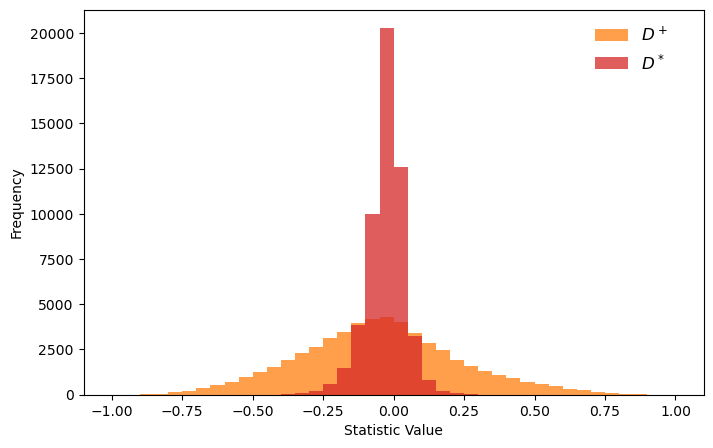

D+: Mean= -0.04986748024552127 Std. Dev.= 0.2843248956447245
D*: Mean= -0.027718641339090452 Std. Dev.= 0.06691099690851424


In [3]:
# Denisova Multiple lineages
df_dstar = pd.read_csv("results/empirical/merged/dstar.tsv", sep="\t", skiprows=2, skipfooter=1, header=0)
df_dplus = pd.read_csv("results/empirical/merged/dplus.tsv", sep="\t", skiprows=3, skipfooter=2, header=0)
df_hmmix = pd.read_csv("results/empirical/merged/hmmix.tsv", sep="\t", header=0)
df_dstar = df_dstar.dropna(subset=['DSTAR'])
df_dplus = df_dplus.dropna(subset=['D+'])
df_hmmix = df_hmmix.dropna(subset=['hmmix'])
plt.figure(figsize=(8,5))
plt.hist(
    df_dplus["D+"], bins=np.arange(-1, 1.05, 0.05),
    histtype='stepfilled', color='tab:orange', alpha=0.75,
)
plt.hist(
    df_dstar["DSTAR"], bins=np.arange(-1, 1.05, 0.05),
    histtype='stepfilled', color='tab:red', alpha=0.75,
)
legend_elements = [
    Patch(facecolor='tab:orange', alpha=0.75, label=r'$D^+$'),
    Patch(facecolor='tab:red', alpha=0.75, label=r'$D^*$'),
]
plt.legend(
    handles=legend_elements, loc='center left',
    bbox_to_anchor=(0.8, 0.9), frameon=False,
    fontsize=12,
)
plt.xlabel("Statistic Value")
plt.ylabel("Frequency")
plt.savefig("denisova_merged_dist.png", dpi=300)
plt.show()

print('D+: Mean=', np.mean(df_dplus["D+"]), 'Std. Dev.=', np.std(df_dplus["D+"]))
print('D*: Mean=', np.mean(df_dstar["DSTAR"]), 'Std. Dev.=', np.std(df_dstar["DSTAR"]))

In [4]:
df_dstar_top = df_dstar[df_dstar['DSTAR'] >= df_dstar['DSTAR'].quantile(0.999)].loc[df_dstar["Num_Loci"] >= 10, ["#Block_Num", "Chromosome", "Start_Position", "End_Position", "Num_Loci", "DSTAR"]]
annotate_with_genes(df_dstar_top)

,#Block_Num,Chromosome,Start_Position,End_Position,Num_Loci,DSTAR,genes
2009,2010,chr1,100500127,100549923,135,0.281830,"CDC14A,GPR88"
4868,4869,chr2,15350020,15399910,187,0.402892,"NBAS,RPS26P18"
4869,4870,chr2,15400032,15449785,90,0.343970,NBAS
4870,4871,chr2,15450016,15499925,168,0.391287,NBAS
4871,4872,chr2,15500113,15549983,173,0.367268,NBAS
7120,7121,chr2,131300151,131349960,175,0.294214,"PLEKHB2,FAR2P4,KLF2P4,ARHGAP42P1"
7528,7529,chr2,151700003,151749947,128,0.277121,NEB
7529,7530,chr2,151750166,151800000,128,0.323337,ARL5A
8974,8975,chr2,224000182,224049908,225,0.257698,SERPINE2
10358,10359,chr3,51000035,51049848,107,0.377371,DOCK3


In [5]:
df_dplus_top = df_dplus[df_dplus['D+'] >= df_dplus['D+'].quantile(0.999)].loc[df_dplus["Num_Loci"] >= 10, ["#Block_Num", "Chromosome", "Start_Position", "End_Position", "Num_Loci", "D+"]]
annotate_with_genes(df_dplus_top)
for _, row in df_dplus_top.iterrows():
    print(f"{row['Chromosome']}:{row['Start_Position']}-{row['End_Position']} & {row['D+']}{" & " + (row['genes'] if pd.notna(row['genes']) else "None")} \\\\")

print()
print()
for _, row in df_dstar_top[~df_dstar_top['#Block_Num'].isin(df_dplus_top['#Block_Num'])].iterrows():
    print(f"{row['Chromosome']}:{row['Start_Position']}-{row['End_Position']} & {row['DSTAR']}{" & " + (row['genes'] if pd.notna(row['genes']) else "None")} \\\\")

print()
print()
df_hmmix_top = df_hmmix[df_hmmix['hmmix'] >= df_hmmix['hmmix'].quantile(0.999)].loc[df_hmmix["Num_Loci"] >= 10, ["#Block_Num", "Chromosome", "Start_Position", "End_Position", "Num_Loci", "hmmix"]]
annotate_with_genes(df_hmmix_top)
for _, row in df_hmmix_top.iterrows():
    print(f"{row['Chromosome']}:{row['Start_Position']}-{row['End_Position']} & {row['hmmix']}{" & " + (row['genes'] if pd.notna(row['genes']) else "None")} \\\\")


chr2:13200289-13249928 & 0.836929 & None \\
chr2:15500113-15549983 & 0.827326 & NBAS \\
chr2:81500426-81549853 & 0.897342 & None \\
chr2:81550477-81599616 & 0.867145 & None \\
chr2:103500013-103549989 & 0.899182 & None \\
chr2:103550042-103599596 & 0.921937 & None \\
chr2:151750166-151800000 & 0.861246 & ARL5A \\
chr2:213600128-213649988 & 0.8334 & SPAG16 \\
chr3:51000035-51049848 & 0.853344 & DOCK3 \\
chr3:51050245-51099743 & 0.826569 & DOCK3 \\
chr3:69800121-69849828 & 0.8333 & MITF \\
chr3:71400504-71449831 & 0.839335 & FOXP1 \\
chr3:87750001-87799174 & 0.848428 & HTR1F \\
chr3:102250073-102299796 & 0.900797 & ZPLD1 \\
chr3:102300814-102349721 & 0.851154 & ZPLD1 \\
chr3:162800016-162849589 & 0.911989 & None \\
chr3:162850019-162899638 & 0.929786 & None \\
chr3:190250515-190299949 & 0.830981 & None \\
chr4:33250480-33299726 & 0.846526 & None \\
chr4:94350137-94399948 & 0.883656 & RPL35AP11 \\
chr4:101200011-101249635 & 0.84719 & PPP3CA,MIR8066 \\
chr4:102750310-102799902 & 0.839853 &

In [14]:
print(df_dplus_top['Chromosome'].astype(str) + "_" + ((df_dplus_top['Start_Position'].astype(int) // 50_000) * 50_0000).astype(str))
print()
print(df_dstar_top['Chromosome'].astype(str) + "_" + ((df_dstar_top['Start_Position'].astype(int) // 50_000) * 50_0000).astype(str))
print()
set(df_hmmix_top['Chromosome'].astype(str) + "_" + ((df_hmmix_top['Start_Position'] - 1).astype(int)).astype(str))

4825      chr2_132000000
4871      chr2_155000000
6191      chr2_815000000
6192      chr2_815500000
6566     chr2_1035000000
6567     chr2_1035500000
7529     chr2_1517500000
8766     chr2_2136000000
10358     chr3_510000000
10359     chr3_510500000
10734     chr3_698000000
10766     chr3_714000000
11093     chr3_877500000
11324    chr3_1022500000
11325    chr3_1023000000
12535    chr3_1628000000
12536    chr3_1628500000
13084    chr3_1902500000
13909     chr4_332500000
15089     chr4_943500000
15226    chr4_1012000000
15257    chr4_1027500000
16402    chr4_1600000000
17617     chr5_305000000
18237     chr5_651500000
18408     chr5_737000000
18936    chr5_1001000000
21699     chr6_568000000
26731    chr7_1427500000
27760     chr8_349500000
28437     chr8_707000000
28438     chr8_707500000
28439     chr8_708000000
28440     chr8_708500000
28441     chr8_709000000
29649    chr8_1313000000
29940       chr9_7500000
30224     chr9_149500000
31623    chr9_1026000000
33380    chr10_542500000


{'chr10_76550000',
 'chr12_17450000',
 'chr12_46750000',
 'chr12_46800000',
 'chr14_65200000',
 'chr14_96600000',
 'chr15_51850000',
 'chr15_54350000',
 'chr15_58250000',
 'chr16_22700000',
 'chr17_39600000',
 'chr18_63900000',
 'chr18_70750000',
 'chr1_101650000',
 'chr1_221400000',
 'chr21_14150000',
 'chr21_38650000',
 'chr2_163250000',
 'chr2_176600000',
 'chr2_241750000',
 'chr3_13350000',
 'chr3_13400000',
 'chr3_151850000',
 'chr3_154550000',
 'chr3_15650000',
 'chr3_15700000',
 'chr3_15750000',
 'chr3_15800000',
 'chr3_15850000',
 'chr3_175400000',
 'chr3_175450000',
 'chr3_32050000',
 'chr3_58750000',
 'chr3_58800000',
 'chr3_7650000',
 'chr3_76500000',
 'chr3_76550000',
 'chr4_2700000',
 'chr4_43800000',
 'chr5_113550000',
 'chr5_150000000',
 'chr5_150050000',
 'chr6_120600000',
 'chr6_133850000',
 'chr6_136000000',
 'chr6_136150000',
 'chr6_136200000',
 'chr6_136700000',
 'chr6_137550000',
 'chr6_137600000',
 'chr6_137650000',
 'chr7_12250000',
 'chr7_64500000',
 'chr8_23100

   #Block_Num Chromosome_x  Start_Position_x  End_Position_x  Num_Loci_x  \
0        4872         chr2          15500113        15549983         320   
1        7530         chr2         151750166       151800000         317   
2       10359         chr3          51000035        51049848         198   
3       10360         chr3          51050245        51099743         188   
4       13910         chr4          33250480        33299726         302   
5       17618         chr5          30500157        30549954         342   
6       29650         chr8         131300072       131349693         570   
7       30225         chr9          14950160        14999993         390   
8       33381        chr10          54250033        54299565         445   

         D+ genes_x Chromosome_y  Start_Position_y  End_Position_y  \
0  0.827326    NBAS         chr2          15500113        15549983   
1  0.861246   ARL5A         chr2         151750166       151800000   
2  0.853344   DOCK3         c

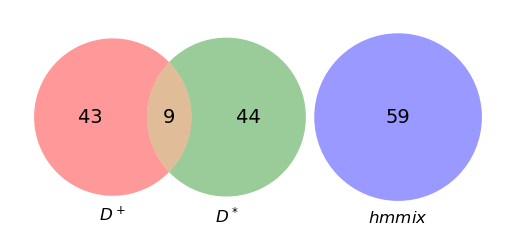

In [6]:
from matplotlib_venn import venn3
v = venn3([set(df_dplus_top['Chromosome'].astype(str) + "_" + ((df_dplus_top['Start_Position'].astype(int) // 50_000) * 50_0000).astype(str)), set(df_dstar_top['Chromosome'].astype(str) + "_" + ((df_dstar_top['Start_Position'].astype(int) // 50_000) * 50_0000).astype(str)), set(df_hmmix_top['Chromosome'].astype(str) + "_" + ((df_hmmix_top['Start_Position'] - 1).astype(int)).astype(str))], set_labels=(r'$D^+$', r'$D^*$', r'$hmmix$'))
for label in v.subset_labels:
    if label:
        label.set_fontsize(14)
print(pd.merge(df_dplus_top, df_dstar_top, on='#Block_Num', how='inner'))
plt.savefig("dplus_dstar_hmmix_venn.png", dpi=300, bbox_inches="tight")
plt.show()

/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_3883/859789129.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  df_dstar = pd.read_csv("results/empirical/subsample_2_2/dstar.tsv", sep="\t", skiprows=2, skipfooter=1, header=0)
/var/folders/_x/fdb_44853vx991yq8wrnpyv40000gn/T/ipykernel_3883/859789129.py:3: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  df_dplus = pd.read_csv("results/empirical/subsample_2_2/dplus.tsv", sep="\t", skiprows=3, skipfooter=2, header=0)


   #Block_Num Chromosome_x  Start_Position_x  End_Position_x  Num_Loci_x  \
0        7530         chr2         151750166       151800000         290   

         D+ Chromosome_y  Start_Position_y  End_Position_y  Num_Loci_y  \
0  0.915108         chr2         151750166       151800000         116   

      DSTAR  
0  0.384067  


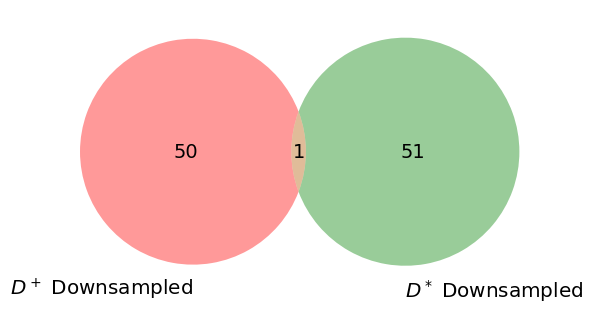

In [8]:
from matplotlib_venn import venn2
df_dstar = pd.read_csv("results/empirical/subsample_2_2/dstar.tsv", sep="\t", skiprows=2, skipfooter=1, header=0)
df_dplus = pd.read_csv("results/empirical/subsample_2_2/dplus.tsv", sep="\t", skiprows=3, skipfooter=2, header=0)
df_hmmix = pd.read_csv("results/empirical/subsample_2_2/hmmix.tsv", sep="\t", header=0)
df_dstar = df_dstar.dropna(subset=['DSTAR'])
df_dplus = df_dplus.dropna(subset=['D+'])
df_hmmix = df_hmmix.dropna(subset=['hmmix'])
df_dstar_top_unequal = df_dstar[df_dstar['DSTAR'] >= df_dstar['DSTAR'].quantile(0.999)].loc[df_dstar["Num_Loci"] >= 10, ["#Block_Num", "Chromosome", "Start_Position", "End_Position", "Num_Loci", "DSTAR"]]
df_dplus_top_unequal = df_dplus[df_dplus['D+'] >= df_dplus['D+'].quantile(0.999)].loc[df_dplus["Num_Loci"] >= 10, ["#Block_Num", "Chromosome", "Start_Position", "End_Position", "Num_Loci", "D+"]]
v = venn2([set(df_dplus_top_unequal['#Block_Num']), set(df_dstar_top_unequal['#Block_Num'])], set_labels=(r'$D^+$ Downsampled', r'$D^*$ Downsampled'))
for label in v.subset_labels:
    if label:
        label.set_fontsize(14)
print(pd.merge(df_dplus_top_unequal, df_dstar_top_unequal, on='#Block_Num', how='inner'))
plt.savefig("dplus_dstar_unequal_venn.png", dpi=300, bbox_inches="tight")

    #Block_Num Chromosome_x  Start_Position_x  End_Position_x  Num_Loci_x  \
0         2010         chr1         100500127       100549923         135   
1         4869         chr2          15350020        15399910         187   
2         4870         chr2          15400032        15449785          90   
3         4871         chr2          15450016        15499925         168   
4         4872         chr2          15500113        15549983         173   
5         7121         chr2         131300151       131349960         175   
6         7529         chr2         151700003       151749947         128   
7         7530         chr2         151750166       151800000         128   
8        10359         chr3          51000035        51049848         107   
9        10360         chr3          51050245        51099743         101   
10       13580         chr4          16750069        16799774         100   
11       13911         chr4          33300092        33349849         188   

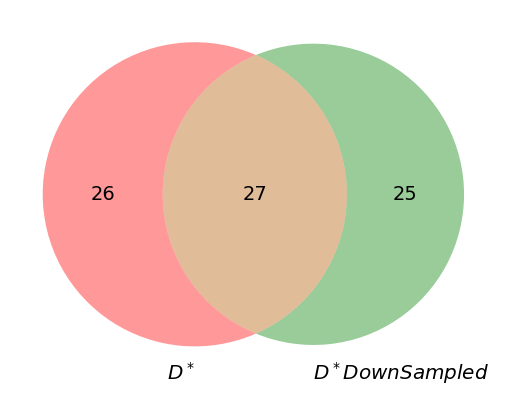

In [9]:
v = venn2([set(df_dstar_top['#Block_Num']), set(df_dstar_top_unequal['#Block_Num'])], set_labels=(r'$D^*$', r'$D^* DownSampled$'))
for label in v.subset_labels:
    if label:
        label.set_fontsize(14)
print(pd.merge(df_dstar_top, df_dstar_top_unequal, on='#Block_Num', how='inner'))
plt.savefig("dstar_unequal_venn.png", dpi=300, bbox_inches="tight")

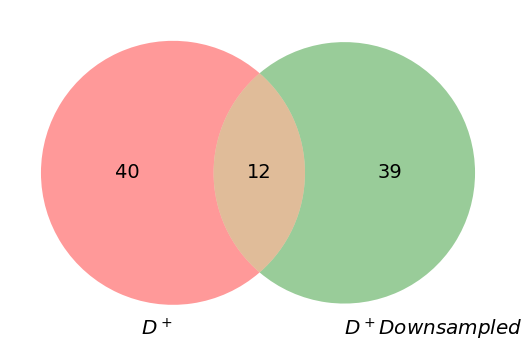

In [10]:
v = venn2([set(df_dplus_top['#Block_Num']), set(df_dplus_top_unequal['#Block_Num'])], set_labels=(r'$D^+$', r'$D^+ Downsampled$'))
for label in v.subset_labels:
    if label:
        label.set_fontsize(14)
#print(pd.merge(df_dplus_top, df_dplus_top_unequal, on='#Block_Num', how='inner'))
plt.savefig("dplus_unequal_venn.png", dpi=300, bbox_inches="tight")

   #Block_Num Chromosome_x  Start_Position_x  End_Position_x  Num_Loci_x  \
0       22081        chr17          39600001        39650000          44   
1       34987         chr3          58750001        58800000          76   
2       34988         chr3          58800001        58850000          35   

    hmmix_x                   genes Chromosome_y  Start_Position_y  \
0  0.735847  NEUROD2,PPP1R1B,STARD3        chr17          39600001   
1  0.764449                CFAP20DC         chr3          58750001   
2  0.764155   CFAP20DC,CFAP20DC-AS1         chr3          58800001   

   End_Position_y  Num_Loci_y   hmmix_y  
0        39650000          30  0.999204  
1        58800000          62  0.999275  
2        58850000          28  0.997954  


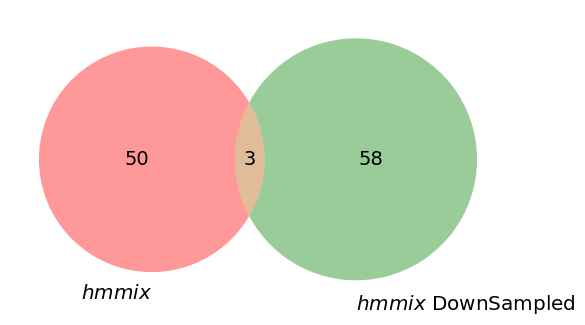

In [11]:
df_hmmix_unequal = df_hmmix[df_hmmix["Num_Loci"] != 0]
df_hmmix_unequal_top = df_hmmix.loc[df_hmmix['hmmix'] >= df_hmmix['hmmix'].quantile(0.999), ["#Block_Num", "Chromosome", "Start_Position", "End_Position", "Num_Loci", "hmmix"]]
v = venn2([set(df_hmmix_top['#Block_Num']), set(df_hmmix_unequal_top['#Block_Num'])], set_labels=(r'$hmmix$', r'$hmmix$ DownSampled'))
for label in v.subset_labels:
    if label:
        label.set_fontsize(14)
print(pd.merge(df_hmmix_top, df_hmmix_unequal_top, on='#Block_Num', how='inner'))
plt.savefig("hammix_unequal_venn.png", dpi=300, bbox_inches="tight")

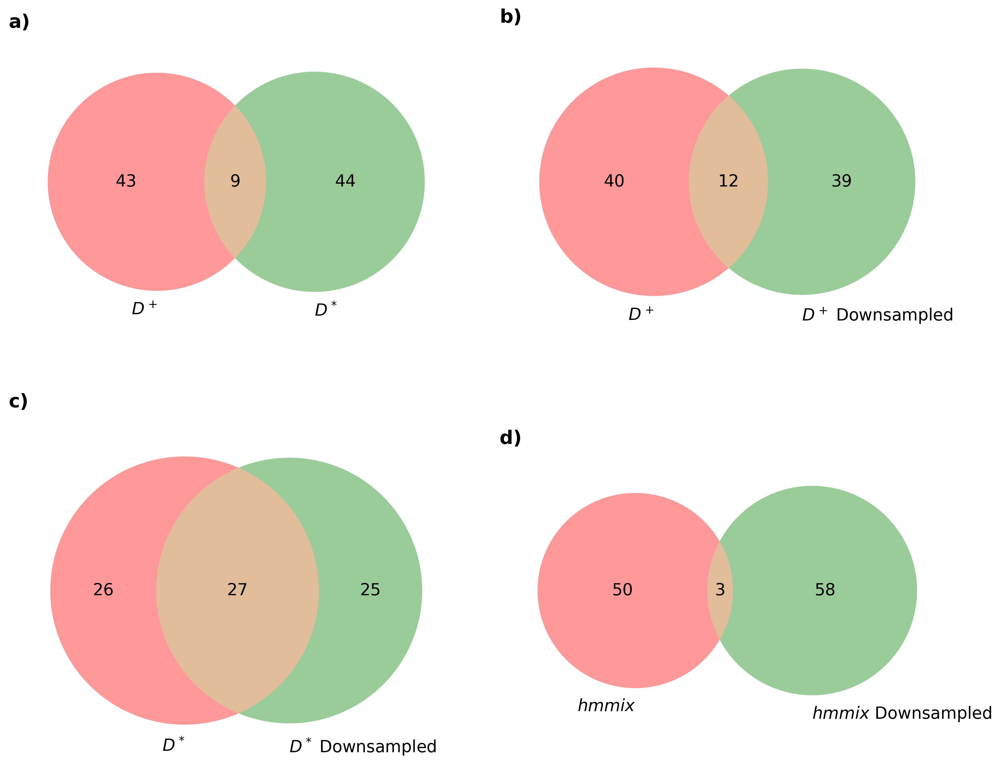

In [32]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

fig = plt.figure(figsize=(12, 10), dpi=300, facecolor='white')

# Manually define four equal-sized square panels
positions = [
    [0.05, 0.53, 0.42, 0.42],  # a
    [0.53, 0.53, 0.42, 0.42],  # b
    [0.05, 0.05, 0.42, 0.42],  # c
    [0.53, 0.05, 0.42, 0.42],  # d
]

axes = [fig.add_axes(pos) for pos in positions]

# -------------------------
# A: D+ vs D*
# -------------------------
v1 = venn2(
    [
        set(
            df_dplus_top['Chromosome'].astype(str)
            + "_"
            + (
                (df_dplus_top['Start_Position'].astype(int) // 50_000)
                * 50_000
            ).astype(str)
        ),
        set(
            df_dstar_top['Chromosome'].astype(str)
            + "_"
            + (
                (df_dstar_top['Start_Position'].astype(int) // 50_000)
                * 50_000
            ).astype(str)
        )
    ],
    set_labels=(r'$D^+$', r'$D^*$'),
    ax=axes[0]
)

# -------------------------
# B: D+ vs D+ Downsampled
# -------------------------
v2 = venn2(
    [
        set(df_dplus_top['#Block_Num']),
        set(df_dplus_top_unequal['#Block_Num'])
    ],
    set_labels=(
        r'$D^+$',
        r'$D^+$ Downsampled'
    ),
    ax=axes[1]
)

# -------------------------
# C: D* vs D* Downsampled
# -------------------------
v3 = venn2(
    [
        set(df_dstar_top['#Block_Num']),
        set(df_dstar_top_unequal['#Block_Num'])
    ],
    set_labels=(
        r'$D^*$',
        r'$D^*$ Downsampled'
    ),
    ax=axes[2]
)

# -------------------------
# D: hmmix vs hmmix Downsampled
# -------------------------
v4 = venn2(
    [
        set(df_hmmix_top['#Block_Num']),
        set(df_hmmix_unequal_top['#Block_Num'])
    ],
    set_labels=(
        r'$hmmix$',
        r'$hmmix$ Downsampled'
    ),
    ax=axes[3]
)

# -------------------------
# Format all Venn diagrams
# -------------------------
for v in [v1, v2, v3, v4]:

    # Number labels
    for label in v.subset_labels:
        if label:
            label.set_fontsize(14)

    # Set labels
    for label in v.set_labels:
        if label:
            label.set_fontsize(14)

# -------------------------
# Panel labels
# -------------------------
for ax, label in zip(axes, ['a)', 'b)', 'c)', 'd)']):
    ax.text(
        -0.03, 1.05,
        label,
        transform=ax.transAxes,
        fontsize=16,
        fontweight='bold',
        va='bottom',
        ha='left'
    )

# Remove axes frames/ticks
for ax in axes:
    ax.set_axis_off()

# Save without bbox_inches='tight'
plt.savefig(
    "venn_diagram.png",
    dpi=300,
    facecolor='white'
)

plt.show()
